# ROME + Coverage — Homework submission

**Course:** LLM4ChipDesign · **Student:** Anuj Apte · **Assignment:** `ROME_Assignment.pdf` (ROME Demo Assignment — Coverage Integration)

Starting point: the original [`ROME_Demo.ipynb`](https://github.com/GUIDE-EDA/GUIDE/blob/main/colab-scripts/ROME_Demo.ipynb).
Integrated by me: the iVerilog + Covered flow from [`coverage_exp`](https://github.com/GUIDE-EDA/GUIDE/tree/main/colab-scripts/coverage_exp).

| Part | What | Section / output folder |
|---|---|---|
| I | Original mux hierarchy `mux2_1 … mux64_1`, final sims, PPA optimizer, Covered on `mux64_1` | Part I · `part1_mux/` |
| II | New hierarchy `half_adder → full_adder → adder4 → adder8`, baseline self-checking TBs, ROME RTL loop | Part II · `part2_adder/` |
| III | Coverage integration, coverage-guided TB refinement, RTL repair with frozen TB, `coverage_history.json` | Part III · `part3_coverage/` |
| IV | Iteration record separating RTL changes from TB changes | Part IV · `iteration_table.md` |

### How the LLM is provided (please read)
All ROME code cells are the course's own and unmodified. With an API key in the environment the notebook runs **live**
exactly like the original (`MODEL=Claude`, `model_choice="claude-sonnet-4-6"` by default).
**The submitted outputs were produced in replay mode**: no API key was available on the machine used, so each LLM call
was answered by Claude (`claude-opus-5-5`) for the exact prompt the pipeline built, stored in `llm_responses/<section>/NNN.json`
together with the full prompt and its SHA-256, and replayed by the wrapper in Section 0.2. All parsing, file writing,
iverilog/vvp simulations, Yosys PPA estimates and Covered runs are real and re-executed on every run.

**One recorded response contains a deliberately seeded fault**, and the notebook prints a NOTE whenever it is served:
the first `adder8` response computes `ovf` for negative overflow only. With replayed responses, a "first-try" LLM mistake
would be one I chose anyway, so instead of passing it off as spontaneous I label it. It is a latent bug the 8-vector
baseline TB cannot see; it exists to exercise the Step 4 path of the assignment (stronger coverage-guided TB exposes a
bug → TB frozen → ROME RTL repair). Every other response is a genuine answer to its prompt.

# 0. Initial setup

In [1]:
#@title Setting up the notebook (portable version of the original install cells)
# Original Colab cells:  !pip install openai anthropic ; !apt-get install -y iverilog verilator gtkwave
#                        + download of oss-cad-suite for Yosys (PPA estimation).
# This version installs only what is missing and adds Covered, which Part III needs.
# Works on Colab and on Debian/Ubuntu (incl. WSL). Native Windows is not supported by Covered.
import os, sys, shutil, subprocess, platform, importlib.util

ROOT = os.path.abspath(os.getcwd())          # the notebook folder, i.e. HW_ROME_Coverage/

def _first_line(cmd):
    try:
        p = subprocess.run(cmd, capture_output=True, text=True)
        return ((p.stdout or "") + (p.stderr or "")).strip().splitlines()[0]
    except Exception as e:
        return "NOT FOUND (" + str(e) + ")"


for pkg in ["openai", "anthropic"]:          # imported by the original utility cell
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

_missing = [t for t in ["iverilog", "vvp", "covered"] if shutil.which(t) is None]
if _missing and platform.system() == "Linux":
    _pre = [] if os.geteuid() == 0 else ["sudo"]
    subprocess.run(_pre + ["apt-get", "update", "-qq"], check=False,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    subprocess.run(_pre + ["apt-get", "install", "-y", "-qq", "iverilog", "covered"], check=False,
                   stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

# Yosys for the PPA loop. The original cell downloads the latest oss-cad-suite to /content (Colab); use it if present.
# Otherwise use YoWASP Yosys (a recent Yosys packaged on PyPI). Distro Yosys (0.33 on Ubuntu 24.04) is too old for
# the original script: it keeps the quotes of `tee -o "<file>"` in the file name and the PPA stat file is never written.
if os.path.isdir("/content/oss-cad-suite/bin"):
    os.environ["PATH"] = "/content/oss-cad-suite/bin:" + os.environ["PATH"]
elif shutil.which("yosys") is None or "Yosys 0.3" in _first_line(["yosys", "-V"]):
    if shutil.which("yowasp-yosys") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yowasp-yosys"], check=False)
    _shim = os.path.join(os.path.expanduser("~"), ".rome_bin")
    os.makedirs(_shim, exist_ok=True)
    with open(os.path.join(_shim, "yosys"), "w") as f:
        f.write('#!/bin/sh\nexec yowasp-yosys "$@"\n')
    os.chmod(os.path.join(_shim, "yosys"), 0o755)
    os.environ["PATH"] = _shim + ":" + os.environ["PATH"]

print("Python   :", sys.version.split()[0], "on", platform.platform())
print("iverilog :", _first_line(["iverilog", "-V"]))
print("covered  :", _first_line(["covered", "-v"]))
print("yosys    :", _first_line(["yosys", "-V"]))
print("ROOT     :", ROOT)

Python   : 3.13.17 on Linux-6.18.44-fc-v153-x86_64-with-glibc2.39
iverilog : Icarus Verilog version 12.0 (stable) ()
covered  : covered-0.7.10


yosys    : Yosys 0.70 (git sha1 28ba3cb92, Release, Clang /workspace/YoWASP/yosys/wasi-sdk-33.0-x86_64-linux/share/cmake/../..//bin/clang++ 22.1.0)
ROOT     : /home/claude/HW_ROME_Coverage


In [2]:
#@title Select Model
#define the model to be used (original cell; only used in LIVE mode)
#model_choice = "gpt-5.2"
#model_choice = "gpt-4o"
model_choice = "claude-sonnet-4-6"
#model_choice = "gemini-2.5-flash"
#model_choice = "nyu-dice-lab/VeriThoughts-Reasoning-14B" #path to your desired Hugging Face model

## 0.1 Original ROME code (unmodified)
The next four cells are copied **verbatim** from `ROME_Demo.ipynb`: utility functions / LLM classes, the RTL feedback loop
(`verilog_loop`), the hierarchical loop (`hier_gen`) and the PPA optimizer (`ppa_verilog_loop`). Nothing in them was edited;
my additions come after them and only *wrap* `generate_verilog` (for replay) and *call* `verilog_loop` (for RTL repair).

In [3]:
#@title Utility functions

import sys
import os
import time
import re
from abc import ABC, abstractmethod

import openai
import anthropic

try:
    import google.genai.errors
    from google import genai
    from google.genai import types
except Exception:
    genai = None
    types = None

################################################################################
### LOGGING
################################################################################

class LogStdoutToFile:
    def __init__(self, filename):
        self._filename = filename
        self._original_stdout = sys.stdout

    def __enter__(self):
        if self._filename:
            sys.stdout = open(self._filename, 'w')
        return self

    def __exit__(self, exc_type, exc_value, traceback):
        if self._filename:
            sys.stdout.close()
        sys.stdout = self._original_stdout


################################################################################
### CONVERSATION CLASS
################################################################################

class Conversation:
    def __init__(self, log_file=None):
        self.messages = []
        self.log_file = log_file

        if self.log_file and os.path.exists(self.log_file):
            open(self.log_file, 'w').close()

    def add_message(self, role, content):
        self.messages.append({'role': role, 'content': content})

        if self.log_file:
            with open(self.log_file, 'a') as file:
                file.write(f"{role}: {content}\n")

    def get_messages(self):
        return self.messages

    def get_last_n_messages(self, n):
        return self.messages[-n:]

    def remove_message(self, index):
        if index < len(self.messages):
            del self.messages[index]

    def get_message(self, index):
        return self.messages[index] if index < len(self.messages) else None

    def clear_messages(self):
        self.messages = []

    def __str__(self):
        return "\n".join([f"{msg['role']}: {msg['content']}" for msg in self.messages])


################################################################################
### LLM CLASSES
################################################################################

class AbstractLLM(ABC):
    @abstractmethod
    def generate(self, conversation: Conversation):
        pass


class ChatGPT(AbstractLLM):
    def __init__(self, model_id=None):
        super().__init__()
        openai.api_key = os.environ["OPENAI_API_KEY"]
        self.client = openai.OpenAI()
        self.model_id = model_id or model_choice

    def generate(self, conversation: Conversation, num_choices=1):
        messages = [
            {
                "role": msg["role"] if msg["role"] in ["system", "user", "assistant"] else "user",
                "content": msg["content"]
            }
            for msg in conversation.get_messages()
        ]

        response = self.client.chat.completions.create(
            model=self.model_id,
            messages=messages,
        )

        return response.choices[0].message.content


class Claude(AbstractLLM):
    def __init__(self, model_id=None):
        super().__init__()
        self.client = anthropic.Anthropic(api_key=os.environ["CLAUDE_API_KEY"])
        self.model_id = model_id or model_choice

    def generate(self, conversation: Conversation, num_choices=1):
        base_delay = 2
        max_retries = 20

        messages = [
            {
                "role": msg["role"] if msg["role"] in ["user", "assistant"] else "user",
                "content": msg["content"]
            }
            for msg in conversation.get_messages()
        ]

        for attempt in range(1, max_retries + 1):
            try:
                output = self.client.messages.create(
                    model=self.model_id,
                    max_tokens=16384,
                    messages=messages
                ).content[0].text
                return output

            except Exception as e:
                wait_time = base_delay * (2 ** (attempt - 1))
                print(f"[Retry {attempt}/{max_retries}] Claude API error: {e}. Retrying in {wait_time:.1f} seconds...")
                time.sleep(wait_time)

        print(f"Failed, exceeded max retries {max_retries}")
        return ""


class Gemini(AbstractLLM):
    def __init__(self, model_id=None):
        super().__init__()
        if genai is None:
            raise ImportError("google-genai is not installed or could not be imported.")
        self.gemini_client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])
        self.model_id = model_id or model_choice

    def generate(self, conversation: Conversation, num_choices=1):
        output = self.gemini_client.models.generate_content(
            model=self.model_id,
            contents=[msg["content"] for msg in conversation.get_messages()],
            config=types.GenerateContentConfig(
                max_output_tokens=16384,
                temperature=0.6,
                topP=0.95,
            )
        ).text

        return output


class HuggingFace(AbstractLLM):
    """
    Local Hugging Face model backend.

    Downloads the selected model from the Hugging Face Hub using snapshot_download,
    then loads it with transformers. The model is cached and reused so it is not
    reloaded every time generate_verilog() is called.
    """

    _loaded_model_id = None
    _tokenizer = None
    _model = None
    _local_model_path = None

    def __init__(
        self,
        model_id=None,
        max_new_tokens=4096,
        temperature=0.2,
        top_p=0.95,
        load_in_4bit=False,
        trust_remote_code=True,
        strip_thinking=True,
    ):
        super().__init__()

        self.model_id = model_id or model_choice

        # If the user accidentally wrote "/org/model", convert it to "org/model".
        # Absolute local paths like "/content/my_model" are still allowed.
        if self.model_id.startswith("/") and not self.model_id.startswith("/content/"):
            self.model_id = self.model_id[1:]

        self.max_new_tokens = max_new_tokens
        self.temperature = temperature
        self.top_p = top_p
        self.load_in_4bit = load_in_4bit
        self.trust_remote_code = trust_remote_code
        self.strip_thinking = strip_thinking

        self.hf_token = (
            os.environ.get("HF_TOKEN")
            or os.environ.get("HUGGINGFACEHUB_API_TOKEN")
            or None
        )

        self.cache_dir = os.environ.get("HF_HOME", "/content/huggingface")

        self._ensure_model_loaded()

    def _get_torch_dtype(self):
        import torch

        if not torch.cuda.is_available():
            return torch.float32

        major, minor = torch.cuda.get_device_capability(0)

        # A100/H100 and newer generally support bf16 well.
        if major >= 8:
            return torch.bfloat16

        # T4/V100 are safer with fp16.
        return torch.float16

    def _ensure_model_loaded(self):
        if HuggingFace._model is not None and HuggingFace._loaded_model_id == self.model_id:
            return

        import torch
        from huggingface_hub import snapshot_download
        from transformers import AutoTokenizer, AutoModelForCausalLM

        print(f"[HuggingFace] Downloading/caching model: {self.model_id}")

        # If this is a local path, do not call snapshot_download.
        if os.path.isdir(self.model_id):
            local_model_path = self.model_id
        else:
            local_model_path = snapshot_download(
                repo_id=self.model_id,
                cache_dir=self.cache_dir,
                token=self.hf_token,
            )

        print(f"[HuggingFace] Loading tokenizer from: {local_model_path}")

        tokenizer = AutoTokenizer.from_pretrained(
            local_model_path,
            trust_remote_code=self.trust_remote_code,
            token=self.hf_token,
        )

        if tokenizer.pad_token_id is None:
            tokenizer.pad_token = tokenizer.eos_token

        torch_dtype = self._get_torch_dtype()

        model_kwargs = {
            "trust_remote_code": self.trust_remote_code,
            "device_map": "auto",
            "low_cpu_mem_usage": True,
            "token": self.hf_token,
        }

        if torch.cuda.is_available() and self.load_in_4bit:
            from transformers import BitsAndBytesConfig

            quantization_config = BitsAndBytesConfig(
                load_in_4bit=False,
                bnb_4bit_quant_type="nf4",
                bnb_4bit_compute_dtype=torch_dtype,
                bnb_4bit_use_double_quant=True,
            )

            model_kwargs["quantization_config"] = quantization_config
        else:
            model_kwargs["torch_dtype"] = torch_dtype

        print("[HuggingFace] Loading model. This can take a few minutes the first time.")

        model = AutoModelForCausalLM.from_pretrained(
            local_model_path,
            **model_kwargs
        )

        model.eval()

        HuggingFace._loaded_model_id = self.model_id
        HuggingFace._tokenizer = tokenizer
        HuggingFace._model = model
        HuggingFace._local_model_path = local_model_path

        print("[HuggingFace] Model loaded successfully.")

    def _format_prompt(self, conversation: Conversation):
        tokenizer = HuggingFace._tokenizer

        messages = []
        for msg in conversation.get_messages():
            role = msg.get("role", "user")
            content = msg.get("content", "")

            if role not in ["system", "user", "assistant"]:
                role = "user"

            messages.append({"role": role, "content": content})

        # Prefer the model's own chat template when available.
        try:
            return tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
        except Exception:
            # Generic fallback for non-chat-template models.
            prompt_parts = []
            for msg in messages:
                prompt_parts.append(f"{msg['role'].upper()}:\n{msg['content']}\n")
            prompt_parts.append("ASSISTANT:\n")
            return "\n".join(prompt_parts)

    def _clean_output(self, text):
        text = text.strip()

        # Helpful for reasoning models that emit <think>...</think>.
        if self.strip_thinking:
            text = re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()

        return text

    def generate(self, conversation: Conversation, num_choices=1):
        import torch

        tokenizer = HuggingFace._tokenizer
        model = HuggingFace._model

        prompt = self._format_prompt(conversation)

        inputs = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=False,
        )

        # With device_map="auto", use the first model parameter's device.
        first_device = next(model.parameters()).device
        inputs = {k: v.to(first_device) for k, v in inputs.items()}

        do_sample = self.temperature is not None and self.temperature > 0

        with torch.inference_mode():
            outputs = model.generate(
                **inputs,
                max_new_tokens=self.max_new_tokens,
                do_sample=do_sample,
                temperature=self.temperature if do_sample else None,
                top_p=self.top_p if do_sample else None,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )

        prompt_len = inputs["input_ids"].shape[-1]
        generated_ids = outputs[0][prompt_len:]

        text = tokenizer.decode(generated_ids, skip_special_tokens=True)
        return self._clean_output(text)


################################################################################
### PARSING AND TEXT MANIPULATION FUNCTIONS
################################################################################

def find_verilog_modules(markdown_string, module_name='top_module'):
    module_pattern1 = r'\bmodule\b\s+\w+\s*\([^)]*\)\s*;.*?endmodule\b'
    module_pattern2 = r'\bmodule\b\s+\w+\s*#\s*\([^)]*\)\s*\([^)]*\)\s*;.*?endmodule\b'

    module_matches1 = re.findall(module_pattern1, markdown_string, re.DOTALL)
    module_matches2 = re.findall(module_pattern2, markdown_string, re.DOTALL)

    module_matches = module_matches1 + module_matches2

    if not module_matches:
        return []

    return module_matches


def write_code_blocks_to_file(markdown_string, module_name, filename):
    code_match = find_verilog_modules(markdown_string, module_name)

    if not code_match:
        print("No Verilog modules found in response")
        exit(3)

    with open(filename, 'w') as file:
        for code_block in code_match:
            file.write(code_block)
            file.write('\n')


def generate_verilog(conv, model_type=None, model_id=""):
    model_type = model_type or os.environ.get("MODEL", "ChatGPT")
    selected_model_id = model_id or model_choice

    if model_type == "ChatGPT":
        model = ChatGPT(model_id=selected_model_id)
    elif model_type == "Claude":
        model = Claude(model_id=selected_model_id)
    elif model_type == "Gemini":
        model = Gemini(model_id=selected_model_id)
    elif model_type == "HuggingFace":
        model = HuggingFace(model_id=selected_model_id)
    else:
        raise ValueError(
            f"Invalid model type: {model_type}. "
            "Expected one of: ChatGPT, Claude, Gemini, HuggingFace."
        )

    return model.generate(conv)

In [4]:
#@title Feedback Loop

import subprocess
import sys
import os
import time
import numpy as np


def _read_files(file_list):
    """Concatenate a list of text files in order. Missing/None entries are ignored."""
    if not file_list:
        return ""

    buf = []
    for p in file_list:
        if not p:
            continue

        try:
            with open(p, "r") as f:
                text = f.read()
                buf.append(text)
                if not text.endswith("\n"):
                    buf.append("\n")
        except FileNotFoundError:
            print(f"[Warning] Previous module file not found and will be skipped: {p}")

    return "".join(buf)


def _truncate_text(s, max_chars=12000):
    """Keep prompts bounded; preserve the end of long logs, where compiler errors usually appear."""
    if s is None:
        return ""

    s = str(s)

    if len(s) <= max_chars:
        return s

    tail = s[-max_chars:]
    return "[...truncated...]\n" + tail


def _add_instruction_prompt(conv, model_type, base_sys_prompt):
    """
    Add the instruction prompt in a way that works for API models and local HF models.

    ChatGPT/Gemini/HuggingFace can use a system role.
    Claude path in the earlier utility cell maps unsupported roles to user,
    but we keep Claude as user here to avoid role issues.
    """
    if model_type == "Claude":
        conv.add_message("user", base_sys_prompt)
    else:
        conv.add_message("system", base_sys_prompt)


def _simulation_passed(stdout_text, stderr_text=""):
    """
    Robust pass/fail detection for your Verilog testbenches.

    Accepts:
      - "All tests passed"
      - "passed!"
      - "Test x passed"

    Rejects:
      - "failed"
      - "Some tests failed"
      - non-empty fatal/error-like stderr
    """
    out = (stdout_text or "")
    err = (stderr_text or "")
    combined = (out + "\n" + err).lower()

    fail_markers = [
        "failed",
        "some tests failed",
        "error running",
        "fatal",
        "syntax error",
    ]

    if any(marker in combined for marker in fail_markers):
        return False

    pass_markers = [
        "all tests passed",
        "passed!",
        "test 1 passed",
        " passed",
    ]

    return any(marker in combined for marker in pass_markers)


def verilog_loop(
    design_prompt,
    module,
    testbench,
    max_iterations,
    model_type=None,
    outdir="",
    log=None,
    prev_modules=None,
    model_id="",
):
    """
    Generate/fix a Verilog module with an LLM, compiling against previously-generated modules.

    Compatible model_type values:
      - "ChatGPT"
      - "Claude"
      - "Gemini"
      - "HuggingFace"

    Key behaviors:
      - The LLM is asked to output ONLY the current module.
      - For compilation, this concatenates:
            [prev_modules...] + [current module]
        into a temporary combined file.
      - After an error, repair iterations only resend:
            (a) previous module version
            (b) most recent compiler/simulation feedback
        to keep prompt size controlled.
    """

    if model_type is None:
        model_type = os.environ.get("MODEL", "ChatGPT")

    valid_model_types = ["ChatGPT", "Claude", "Gemini", "HuggingFace"]
    if model_type not in valid_model_types:
        raise ValueError(
            f"Invalid model_type: {model_type}. "
            f"Expected one of: {valid_model_types}"
        )

    if outdir is None:
        outdir = ""

    outdir = outdir.strip()

    if outdir != "":
        os.makedirs(outdir, exist_ok=True)

    def _outpath(filename):
        if outdir == "":
            return filename
        return os.path.join(outdir, filename)

    # Normalize prev_modules into a list of paths.
    if prev_modules is None:
        prev_modules = []
    elif isinstance(prev_modules, str):
        prev_modules = [prev_modules]

    # Read the testbench so the model can target the test expectations.
    tb_text = ""
    try:
        with open(testbench, "r") as _tb:
            tb_text = _tb.read()
    except Exception as e:
        print(f"[Warning] Could not read testbench file: {testbench}")
        print(f"[Warning] Exception: {e}")
        tb_text = ""

    base_sys_prompt = (
        "You are an autocomplete engine for Verilog code. "
        "Given a Verilog module specification, you will provide a completed Verilog module in response. "
        "You will provide completed Verilog modules for all specifications, and will not create any supplementary modules. "
        "Given a Verilog module that is incorrect or has a compilation error, you will suggest corrections to the module. "
        "You will not refuse. "
        "You will not generate explanations, comments outside the code, Markdown, or testbenches. "
        "IMPORTANT: Output ONLY the Verilog code for the requested module. "
        "Do NOT repeat any previous modules. "
        "Do NOT wrap the code in triple backticks. "
        "Format your response as one complete corrected Verilog module, from module declaration through endmodule. "
        "Use Verilog-2001 only unless explicitly told otherwise."
    )

    def _new_conv_full_context():
        """Initial attempt: include testbench and design prompt."""
        conv = Conversation(log_file=log)

        _add_instruction_prompt(conv, model_type, base_sys_prompt)

        if tb_text.strip():
            conv.add_message(
                "user",
                "The following is the testbench that will be used to compile/simulate your module. "
                "Do NOT generate a testbench or modify it. Only use it to ensure your module compiles and passes.\n\n"
                "```verilog\n"
                + tb_text
                + "\n```\n",
            )

        conv.add_message("user", design_prompt)
        return conv

    def _new_conv_repair_only(prev_module_text, last_error_text):
        """Repair attempts: only previous module plus most recent error feedback."""
        conv = Conversation(log_file=log)

        _add_instruction_prompt(conv, model_type, base_sys_prompt)

        prompt = (
            "Fix the following Verilog module so it compiles and passes the testbench. "
            "Output ONLY the full corrected module. "
            "Do not output explanations. "
            "Do not output a testbench. "
            "Do not use Markdown fences.\n\n"
            "Previous version of the module:\n"
            "```verilog\n"
            + prev_module_text
            + "\n```\n\n"
            "Most recent compiler/simulation output:\n"
            "```\n"
            + _truncate_text(last_error_text)
            + "\n```\n"
        )

        conv.add_message("user", prompt)
        return conv

    conv = _new_conv_full_context()

    success = False
    timeout = False

    iterations = 0
    timelist_total = []
    timelist_gen = []
    timelist_error = []

    module_file = _outpath(module + ".v")
    combined_file = _outpath(module + "__combined.v")
    sim_output_file = _outpath(module)

    status = ""
    last_module_text = ""
    last_error_text = ""

    while not (success or timeout):
        print(f"\n========== Iteration {iterations} / {max_iterations} ==========")

        start_total = time.time()

        # Generate or repair only the current module.
        response = generate_verilog(conv, model_type, model_id=model_id)

        end_gen = time.time()
        start_error = time.time()

        if response is None:
            response = ""

        conv.add_message("assistant", response)

        # Write raw model response for debugging, especially useful for local HF models.
        raw_response_file = _outpath("raw_response_iter_" + str(iterations) + ".txt")
        with open(raw_response_file, "w") as f:
            f.write(response)

        # Extract and write just the current module.
        try:
            write_code_blocks_to_file(response, module, module_file)
        except SystemExit:
            status = "No Verilog module found in model response"
            print(status)

            last_error_text = (
                "The model response did not contain a complete Verilog module. "
                "It must output exactly one complete module from module declaration through endmodule.\n\n"
                "Raw model response:\n"
                + _truncate_text(response)
            )

            last_module_text = response
            conv = _new_conv_repair_only(last_module_text, last_error_text)

            if iterations >= max_iterations:
                timeout = True

            iterations += 1
            end_time = time.time()
            timelist_gen.append(end_gen - start_total)
            timelist_error.append(end_time - start_error)
            timelist_total.append(end_time - start_total)
            continue

        # Build concatenated source for compilation:
        # previous modules + current module.
        prev_text = _read_files(prev_modules)

        with open(module_file, "r") as f:
            curr_text = f.read()

        last_module_text = curr_text

        with open(combined_file, "w") as f:
            f.write(prev_text)
            if prev_text and not prev_text.endswith("\n"):
                f.write("\n")
            f.write(curr_text)
            if curr_text and not curr_text.endswith("\n"):
                f.write("\n")

        # Compile with iVerilog.
        compile_cmd = [
            "iverilog",
            "-o",
            sim_output_file,
            combined_file,
            testbench,
        ]

        proc = subprocess.run(
            compile_cmd,
            capture_output=True,
            text=True,
        )

        success = False

        if proc.returncode != 0:
            status = "Error compiling testbench"
            print(status)

            last_error_text = (
                "iverilog failed.\n\n"
                "Command:\n"
                + " ".join(compile_cmd)
                + "\n\nstderr:\n"
                + (proc.stderr or "")
                + "\nstdout:\n"
                + (proc.stdout or "")
            )

        elif proc.stderr.strip() != "":
            # Treat warnings as repair feedback.
            # This keeps generated modules cleaner for later synthesis/PPA.
            status = "Warnings compiling testbench"
            print(status)

            last_error_text = (
                "iverilog produced warnings.\n\n"
                "Command:\n"
                + " ".join(compile_cmd)
                + "\n\nstderr:\n"
                + (proc.stderr or "")
                + "\nstdout:\n"
                + (proc.stdout or "")
            )

        else:
            # Run simulation.
            run_cmd = ["vvp", sim_output_file]

            proc = subprocess.run(
                run_cmd,
                capture_output=True,
                text=True,
            )

            result_stdout = proc.stdout or ""
            result_stderr = proc.stderr or ""

            print(result_stdout)

            if proc.returncode != 0:
                status = "Error running testbench"
                print(status)

                last_error_text = (
                    "vvp simulation failed.\n\n"
                    "Command:\n"
                    + " ".join(run_cmd)
                    + "\n\nstdout:\n"
                    + result_stdout
                    + "\nstderr:\n"
                    + result_stderr
                )

            elif not _simulation_passed(result_stdout, result_stderr):
                status = "Testbench did not report success"
                print(status)

                last_error_text = (
                    "Simulation completed, but the output did not indicate success.\n\n"
                    "stdout:\n"
                    + result_stdout
                    + "\nstderr:\n"
                    + result_stderr
                )

            else:
                status = "Testbench ran successfully"
                print(status)

                last_error_text = ""
                success = True

        # Write bounded iteration log.
        with open(_outpath("log_iter_" + str(iterations) + ".txt"), "w") as file:
            file.write("\n".join(str(i) for i in conv.get_messages()))
            file.write("\n\nIteration status: " + status + "\n")

            if last_error_text:
                file.write("\nMost recent feedback:\n")
                file.write(_truncate_text(last_error_text))

        if not success:
            # Keep future repair prompts small.
            conv = _new_conv_repair_only(last_module_text, last_error_text)

        if iterations >= max_iterations:
            timeout = True

        iterations += 1

        end_time = time.time()
        timelist_gen.append(end_gen - start_total)
        timelist_error.append(end_time - start_error)
        timelist_total.append(end_time - start_total)

    print("\n========== Feedback Loop Complete ==========")
    print("Final status: ", status)
    print("Total time: ", np.sum(timelist_total))
    print("Generation time: ", np.sum(timelist_gen))
    print("Error handling time: ", np.sum(timelist_error))

    return (
        np.sum(timelist_total),
        np.sum(timelist_gen),
        np.sum(timelist_error),
    )

In [5]:
#@title Hierarchical Loop

import os
import re
import numpy as np


def _normalize_to_list(x):
    """Normalize None/string/list/tuple into a list."""
    if x is None or x == "":
        return []
    if isinstance(x, str):
        return [x]
    return list(x)


def _resolve_prev_module_path(item):
    """
    Resolve previous module reference into a .v path.

    Supported forms:
      - "mux2_1"              -> "./mux2_1/mux2_1.v"
      - "./mux2_1/mux2_1.v"   -> "./mux2_1/mux2_1.v"
      - ("mux2_1", "...", ...) -> "./mux2_1/mux2_1.v"
    """
    if isinstance(item, (list, tuple)):
        item = item[0]

    item = str(item)

    if item.endswith(".v"):
        return item

    return os.path.join("./" + item, item + ".v")


def _extract_verilog_interfaces(verilog_text):
    """
    Extract module declarations/interfaces from Verilog text.

    This is useful for hierarchical prompting because the current module usually
    only needs previous module names and port lists, not full implementations.
    """
    if not verilog_text:
        return ""

    # Match:
    #   module name (...);
    #   module name #(parameters...) (...);
    pattern = r'\bmodule\s+[A-Za-z_][A-Za-z0-9_]*\s*(?:#\s*\(.*?\)\s*)?\(.*?\)\s*;'

    matches = re.findall(pattern, verilog_text, flags=re.DOTALL)

    if not matches:
        return ""

    cleaned = []
    for m in matches:
        cleaned.append(m.strip() + "\nendmodule")

    return "\n\n".join(cleaned) + "\n"


def _read_prev_modules_for_prompt(prev_verilog_files, context_mode="interfaces", max_chars=24000):
    """
    Read previous modules for LLM context.

    context_mode:
      - "interfaces": include only module declarations, best for HF/local models.
      - "full": include full previous module bodies.
      - "none": include no previous code in the prompt.

    Compilation still receives the full previous .v files through verilog_loop(prev_modules=...).
    """
    if context_mode == "none":
        return ""

    chunks = []

    for p in prev_verilog_files:
        if not p:
            continue

        if not os.path.exists(p):
            print(f"[Warning] Previous module file not found for prompt context: {p}")
            continue

        with open(p, "r") as f:
            txt = f.read()

        if context_mode == "interfaces":
            txt = _extract_verilog_interfaces(txt)

        if txt.strip():
            chunks.append("// File: " + p + "\n" + txt.strip() + "\n")

    prev_text = "\n".join(chunks)

    if len(prev_text) > max_chars:
        # Keep the most recent context, because later modules tend to depend on recent modules.
        prev_text = "[...previous module context truncated...]\n" + prev_text[-max_chars:]

    return prev_text


def _call_verilog_loop_compatible(
    prompt,
    module,
    testbench,
    max_iterations,
    model,
    outdir,
    log,
    prev_verilog_files,
    model_id="",
):
    """
    Calls the updated verilog_loop with model_id support.
    Falls back to the older signature if needed.
    """
    try:
        return verilog_loop(
            prompt,
            module,
            testbench,
            max_iterations,
            model,
            outdir,
            log,
            prev_modules=prev_verilog_files,
            model_id=model_id,
        )
    except TypeError as e:
        if "model_id" not in str(e):
            raise

        print("[Warning] verilog_loop does not accept model_id. Falling back to old signature.")

        return verilog_loop(
            prompt,
            module,
            testbench,
            max_iterations,
            model,
            outdir,
            log,
            prev_modules=prev_verilog_files,
        )


def hier_gen(
    submods,
    prevsubmods="",
    max_iterations=10,
    model_type=None,
    model_id="",
    testbench_template="./{module}tb.v",
    prompt_prev_context_chars=24000,
    prev_context_mode="interfaces",
):
    """
    Hierarchically generate a design by building submodules in order.

    submods:
      list of tuples/lists:
        [
          (file_basename, human_name, io_string),
          ...
        ]

      Example:
        [
          ("mux2_1", "2-to-1 mux", "input wire a, input wire b, input wire sel, output wire y"),
          ("mux4_1", "4-to-1 mux", "input wire [3:0] in, input wire [1:0] sel, output wire y"),
        ]

    prevsubmods:
      Optional previous module references already generated before this call.

      Supported:
        - ""
        - None
        - "mux2_1"
        - ["mux2_1", "mux4_1"]
        - ["./mux2_1/mux2_1.v"]
        - previous submod tuples/lists

    model_type:
      Optional. If None, uses os.environ["MODEL"].

      Supported by the earlier utility cell:
        - "ChatGPT"
        - "Claude"
        - "Gemini"
        - "HuggingFace"

    model_id:
      Optional model override passed through to verilog_loop/generate_verilog.

      Example:
        model_id="nyu-dice-lab/VeriThoughts-Reasoning-14B"

    testbench_template:
      Default assumes testbenches are named:
        ./module_nametb.v

      You can also use:
        "./testbenches/{module}_tb.v"

    prev_context_mode:
      - "interfaces": best default, includes previous module port declarations only.
      - "full": includes full previous module code in prompt.
      - "none": does not include previous modules in prompt.

      Regardless of this setting, previous modules are still passed to iVerilog
      through verilog_loop(prev_modules=...).
    """

    if model_type is None:
        model_type = os.environ.get("MODEL", "ChatGPT")

    valid_context_modes = ["interfaces", "full", "none"]
    if prev_context_mode not in valid_context_modes:
        raise ValueError(
            f"Invalid prev_context_mode: {prev_context_mode}. "
            f"Expected one of: {valid_context_modes}"
        )

    totaltime = []
    gentime = []
    errortime = []

    prev_verilog_files = []

    # Add previously generated external modules, if any.
    for s in _normalize_to_list(prevsubmods):
        p = _resolve_prev_module_path(s)
        if os.path.exists(p):
            prev_verilog_files.append(p)
        else:
            print(f"[Warning] prevsubmod file does not exist and will be skipped: {p}")

    if not submods:
        print("[Warning] No submodules provided.")
        return (0, 0, 0)

    overall = submods[-1][1]

    for i in range(len(submods)):
        fcurr = submods[i][0]   # file/module basename
        curr = submods[i][1]    # human-readable name
        iocurr = submods[i][2]  # port list string

        outdir = "./" + fcurr
        os.makedirs(outdir, exist_ok=True)

        prev_text = _read_prev_modules_for_prompt(
            prev_verilog_files,
            context_mode=prev_context_mode,
            max_chars=prompt_prev_context_chars,
        )

        if i == 0 and len(prev_verilog_files) == 0:
            prompt = (
                "// We will be generating a "
                + overall
                + " hierarchically in Verilog.\n"
                "// IMPORTANT: Output ONLY the module requested below.\n"
                "// Do NOT generate any previous modules, future modules, explanations, or testbenches.\n"
                "// Use Verilog-2001 only.\n"
                "// Begin by generating: "
                + curr
                + "\n\n"
                "module "
                + fcurr
                + "("
                + iocurr
                + ");\n"
                "// Insert code here\n"
                "endmodule\n"
            )
        else:
            prompt = (
                "// We are generating a "
                + overall
                + " hierarchically in Verilog.\n"
                "// Use Verilog-2001 only.\n\n"
                "// Previously generated modules are shown below for reference only.\n"
                "// You may instantiate them, but you must NOT repeat their definitions.\n\n"
                + prev_text
                + "\n"
                "// IMPORTANT: Output ONLY the new module requested below.\n"
                "// Do NOT repeat any previous modules.\n"
                "// Do NOT generate explanations, Markdown fences, or a testbench.\n"
                "// Now generate: "
                + curr
                + "\n\n"
                "module "
                + fcurr
                + "("
                + iocurr
                + ");\n"
                "// Insert code here\n"
                "endmodule\n"
            )

        module = fcurr
        testbench = testbench_template.format(module=fcurr, name=fcurr)
        model = model_type
        log = os.path.join(outdir, "log.txt")

        if not os.path.exists(testbench):
            print(f"[Warning] Testbench file does not exist yet: {testbench}")
            print("[Warning] verilog_loop will still run, but iVerilog will fail unless the file exists.")

        total, gen, error = _call_verilog_loop_compatible(
            prompt=prompt,
            module=module,
            testbench=testbench,
            max_iterations=max_iterations,
            model=model,
            outdir=outdir,
            log=log,
            prev_verilog_files=prev_verilog_files,
            model_id=model_id,
        )

        print("Module ", i + 1, " done: ", curr)

        totaltime.append(total)
        gentime.append(gen)
        errortime.append(error)

        # Add the current module file to the compilation context for subsequent modules.
        curr_module_file = os.path.join(outdir, module + ".v")

        if os.path.exists(curr_module_file):
            prev_verilog_files.append(curr_module_file)
        else:
            print(f"[Warning] Expected generated module file not found: {curr_module_file}")

    overall_total = np.sum(totaltime)
    overall_gen = np.sum(gentime)
    overall_error = np.sum(errortime)

    print("Overall Total time: ", overall_total)
    print("Overall Generation Time: ", overall_gen)
    print("Overall Error handling time: ", overall_error)

    return (overall_total, overall_gen, overall_error)

In [6]:
#@title PPA Optimizer Loop

#@title PPA Optimization Loop (Yosys no-liberty + iVerilog correctness)

import subprocess
import sys
import os
import time
import math
import json
import re
import shutil
import numpy as np


################################################################################
### GENERAL HELPERS
################################################################################

def _read_files(file_list):
    """Concatenate a list of text files in order. Missing/None entries are ignored."""
    if not file_list:
        return ""

    buf = []

    for p in file_list:
        if not p:
            continue

        if not os.path.exists(p):
            print(f"[Warning] Previous module file not found and will be skipped: {p}")
            continue

        with open(p, "r") as f:
            txt = f.read()

        buf.append(txt)

        if txt and not txt.endswith("\n"):
            buf.append("\n")

    return "".join(buf)


def _truncate_text(s, max_chars=12000):
    """Keep prompts bounded; preserve the tail of long logs."""
    if s is None:
        return ""

    s = str(s)

    if len(s) <= max_chars:
        return s

    return "[...truncated...]\n" + s[-max_chars:]


def _shell_quote_for_yosys(path):
    """Quote filenames for use inside a .ys script."""
    return '"' + str(path).replace("\\", "\\\\").replace('"', '\\"') + '"'


def _safe_float(x, default=None):
    try:
        return float(x)
    except Exception:
        return default


def _safe_int(x, default=None):
    try:
        return int(x)
    except Exception:
        return default


def _first_regex(text, patterns, cast=float):
    for pat in patterns:
        m = re.search(pat, text, flags=re.IGNORECASE | re.MULTILINE | re.DOTALL)
        if m:
            try:
                return cast(m.group(1))
            except Exception:
                pass

    return None


def _normalize_clk_signal(clk_signal):
    """Treat None, '', 'None', 'none', etc. as no clock."""
    if clk_signal is None:
        return None

    s = str(clk_signal).strip()

    if s == "" or s.lower() == "none":
        return None

    return s


def _has_any_parsed_metric(metrics):
    if not metrics:
        return False

    keys = [
        "transistor_est",
        "area_cmos",
        "num_cells",
        "num_wire_bits",
        "timing_proxy",
    ]

    return any(metrics.get(k) is not None for k in keys)


def _is_verbose(verbose):
    return str(verbose).strip().lower() in ["1", "true", "yes", "y"]


def _write_text(path, text):
    with open(path, "w") as f:
        f.write(text)


def _add_instruction_prompt(conv, model_type, base_sys_prompt):
    """
    Add the instruction prompt in a provider-compatible way.

    ChatGPT, Gemini, and HuggingFace can use the system role through the
    Conversation abstraction from the previous utility cell.

    Claude is kept as user to avoid unsupported-role issues.
    """
    if model_type == "Claude":
        conv.add_message("user", base_sys_prompt)
    else:
        conv.add_message("system", base_sys_prompt)


def _generate_verilog_compatible(conv, model_type, model_id=""):
    """
    Calls generate_verilog with model_id support when available.
    Falls back to the older two-argument signature if needed.
    """
    try:
        return generate_verilog(conv, model_type, model_id=model_id)
    except TypeError as e:
        if "model_id" not in str(e):
            raise

        print("[Warning] generate_verilog does not accept model_id. Falling back to old signature.")
        return generate_verilog(conv, model_type)


def _simulation_passed(stdout_text, stderr_text=""):
    """
    Robust pass/fail detection for Verilog testbenches.

    Accepts:
      - All tests passed
      - passed!
      - Test x passed
      - Test x passed!

    Rejects:
      - failed
      - Some tests failed
      - fatal/error markers
    """
    out = stdout_text or ""
    err = stderr_text or ""
    combined = (out + "\n" + err).lower()

    fail_markers = [
        "failed",
        "some tests failed",
        "fatal",
        "syntax error",
        "error:",
    ]

    if any(marker in combined for marker in fail_markers):
        return False

    pass_markers = [
        "all tests passed",
        "passed!",
        "test 1 passed",
        " passed",
    ]

    return any(marker in combined for marker in pass_markers)


################################################################################
### YOSYS PARSING
################################################################################

def _parse_yosys_stat_text(stat_text):
    """
    Parse Yosys `stat -tech cmos` output.

    Supports both styles:
      Older style:
        Number of wires: ...
        Number of cells: ...
        Chip area for module ...: ...

      Newer compact style:
        6 wires
        165 wire bits
        61 cells
        Estimated number of transistors: 722
    """
    metrics = {}

    metrics["num_wires"] = _first_regex(
        stat_text,
        [
            r"Number of wires:\s*([0-9]+)",
            r"^\s*([0-9]+)\s+wires\s*$",
        ],
        int,
    )

    metrics["num_wire_bits"] = _first_regex(
        stat_text,
        [
            r"Number of wire bits:\s*([0-9]+)",
            r"^\s*([0-9]+)\s+wire bits\s*$",
        ],
        int,
    )

    metrics["num_public_wires"] = _first_regex(
        stat_text,
        [
            r"Number of public wires:\s*([0-9]+)",
            r"^\s*([0-9]+)\s+public wires\s*$",
        ],
        int,
    )

    metrics["num_public_wire_bits"] = _first_regex(
        stat_text,
        [
            r"Number of public wire bits:\s*([0-9]+)",
            r"^\s*([0-9]+)\s+public wire bits\s*$",
        ],
        int,
    )

    metrics["num_memories"] = _first_regex(
        stat_text,
        [
            r"Number of memories:\s*([0-9]+)",
            r"^\s*([0-9]+)\s+memories\s*$",
        ],
        int,
    )

    metrics["num_memory_bits"] = _first_regex(
        stat_text,
        [
            r"Number of memory bits:\s*([0-9]+)",
            r"^\s*([0-9]+)\s+memory bits\s*$",
        ],
        int,
    )

    metrics["num_processes"] = _first_regex(
        stat_text,
        [
            r"Number of processes:\s*([0-9]+)",
            r"^\s*([0-9]+)\s+processes\s*$",
        ],
        int,
    )

    metrics["num_cells"] = _first_regex(
        stat_text,
        [
            r"Number of cells:\s*([0-9]+)",
            r"^\s*([0-9]+)\s+cells\s*$",
        ],
        int,
    )

    transistor_est = _first_regex(
        stat_text,
        [
            r"Estimated number of transistors:\s*([0-9]+(?:\.[0-9]+)?)",
            r"Chip area for module .*?:\s*([0-9]+(?:\.[0-9]+)?)",
        ],
        float,
    )

    metrics["transistor_est"] = transistor_est

    # Backward-compatible area-like proxy.
    metrics["area_cmos"] = transistor_est

    return metrics


def _parse_yosys_timeest_text(time_text):
    """
    Parse a timing proxy from Yosys timeest output.

    Returns None if no timing proxy can be found.
    """
    metrics = {}

    if re.search(r"No domain .* in module", time_text or "", flags=re.IGNORECASE):
        metrics["timing_proxy"] = None
        return metrics

    timing_proxy = _first_regex(
        time_text,
        [
            r"critical path.*?([0-9]+(?:\.[0-9]+)?)\s*AIG",
            r"([0-9]+(?:\.[0-9]+)?)\s*AIG nodes",
            r"([0-9]+(?:\.[0-9]+)?)\s*nodes.*critical path",
            r"Estimated.*?([0-9]+(?:\.[0-9]+)?)",
            r"Delay\s*[:=]\s*([0-9]+(?:\.[0-9]+)?)",
        ],
        float,
    )

    metrics["timing_proxy"] = timing_proxy

    return metrics


def _format_metrics(metrics):
    if metrics is None:
        return "None"

    parts = []

    if metrics.get("transistor_est") is not None:
        parts.append("transistor_est={:.0f}".format(metrics["transistor_est"]))
    elif metrics.get("area_cmos") is not None:
        parts.append("area_cmos={:.3f}".format(metrics["area_cmos"]))

    if metrics.get("timing_proxy") is not None:
        parts.append("timing_proxy={:.3f}".format(metrics["timing_proxy"]))

    if metrics.get("num_cells") is not None:
        parts.append("num_cells={}".format(metrics["num_cells"]))

    if metrics.get("num_wire_bits") is not None:
        parts.append("wire_bits={}".format(metrics["num_wire_bits"]))

    return ", ".join(parts) if parts else "No parsed metrics"


################################################################################
### YOSYS ESTIMATION
################################################################################

def yosys_estimate_no_liberty(verilog_file, top_module, clk_signal=None, outdir=""):
    """
    Run a coarse no-liberty Yosys estimate.

    Uses:
      - stat -top <top> -tech cmos
      - optional timeest -clk <clk>

    Returns:
      {
        "ok": bool,
        "metrics": dict,
        "stat_text": str,
        "time_text": str,
        "yosys_stdout": str,
        "yosys_stderr": str,
        "error": str
      }
    """
    if outdir:
        os.makedirs(outdir, exist_ok=True)

    clk_signal = _normalize_clk_signal(clk_signal)

    script_path = os.path.join(outdir, "ppa_estimate.ys") if outdir else "ppa_estimate.ys"
    stat_path = os.path.join(outdir, "ppa_stat.txt") if outdir else "ppa_stat.txt"
    time_path = os.path.join(outdir, "ppa_time.txt") if outdir else "ppa_time.txt"

    ys = []
    ys.append("read_verilog {}".format(_shell_quote_for_yosys(verilog_file)))
    ys.append("hierarchy -check -top {}".format(top_module))
    ys.append("proc")
    ys.append("opt")
    ys.append("memory")
    ys.append("opt")
    ys.append("fsm")
    ys.append("opt")
    ys.append("techmap")
    ys.append("opt")
    ys.append("clean")
    ys.append(
        "tee -o {} stat -top {} -tech cmos".format(
            _shell_quote_for_yosys(stat_path),
            top_module,
        )
    )

    if clk_signal is not None:
        ys.append("flatten")
        ys.append(
            "tee -o {} timeest -clk {}".format(
                _shell_quote_for_yosys(time_path),
                clk_signal,
            )
        )

    with open(script_path, "w") as f:
        f.write("\n".join(ys) + "\n")

    proc = subprocess.run(
        ["yosys", "-s", script_path],
        capture_output=True,
        text=True,
    )

    stdout = proc.stdout or ""
    stderr = proc.stderr or ""

    result = {
        "ok": False,
        "metrics": {},
        "stat_text": "",
        "time_text": "",
        "yosys_stdout": stdout,
        "yosys_stderr": stderr,
        "error": "",
    }

    if proc.returncode != 0:
        result["error"] = "Yosys failed.\nstdout:\n{}\nstderr:\n{}".format(stdout, stderr)
        return result

    stat_text = ""
    time_text = ""

    if os.path.exists(stat_path):
        with open(stat_path, "r") as f:
            stat_text = f.read()

    if os.path.exists(time_path):
        with open(time_path, "r") as f:
            time_text = f.read()

    metrics = _parse_yosys_stat_text(stat_text)
    metrics.update(_parse_yosys_timeest_text(time_text))

    if metrics.get("transistor_est") is not None:
        metrics["power_proxy"] = metrics["transistor_est"]
    else:
        metrics["power_proxy"] = metrics.get("num_cells")

    result["ok"] = True
    result["metrics"] = metrics
    result["stat_text"] = stat_text
    result["time_text"] = time_text

    if not _has_any_parsed_metric(metrics):
        result["error"] = "Yosys ran successfully, but no metrics were parsed."

    return result


################################################################################
### PPA SCORING
################################################################################

def _component_ratio(candidate_value, baseline_value):
    if candidate_value is None or baseline_value is None:
        return None

    if baseline_value == 0:
        return None

    return float(candidate_value) / float(baseline_value)


def _relative_ppa_score(
    candidate_metrics,
    baseline_metrics,
    area_weight=0.60,
    timing_weight=0.30,
    power_weight=0.10,
):
    """
    Lower is better.

    Uses relative ratios against the current best correct design.
    """
    used_weight = 0.0
    score = 0.0

    cand_area = candidate_metrics.get("transistor_est", candidate_metrics.get("area_cmos"))
    base_area = baseline_metrics.get("transistor_est", baseline_metrics.get("area_cmos"))

    area_ratio = _component_ratio(cand_area, base_area)

    if area_ratio is not None:
        score += area_weight * area_ratio
        used_weight += area_weight

    timing_ratio = _component_ratio(
        candidate_metrics.get("timing_proxy"),
        baseline_metrics.get("timing_proxy"),
    )

    if timing_ratio is not None:
        score += timing_weight * timing_ratio
        used_weight += timing_weight

    power_ratio = _component_ratio(
        candidate_metrics.get("power_proxy"),
        baseline_metrics.get("power_proxy"),
    )

    if power_ratio is not None:
        score += power_weight * power_ratio
        used_weight += power_weight

    if used_weight == 0.0:
        return math.inf

    return score / used_weight


def _is_better_ppa(candidate_metrics, best_metrics, min_improvement=0.0025):
    """
    Returns True only when candidate has parsed metrics and is better.
    """
    if not _has_any_parsed_metric(candidate_metrics):
        return False

    if best_metrics is None or not _has_any_parsed_metric(best_metrics):
        return True

    cand_score = _relative_ppa_score(candidate_metrics, best_metrics)

    # Best-vs-itself is effectively 1.0, so lower is better.
    return cand_score < (1.0 - min_improvement)


################################################################################
### IVERILOG CHECK
################################################################################

def _compile_and_run_iverilog(module_name, combined_file, testbench, outdir):
    """
    Return:
      {
        "ok": bool,
        "status": str,
        "error_text": str,
        "stdout": str,
        "stderr": str
      }
    """
    exe_path = os.path.join(outdir, module_name) if outdir else module_name

    proc = subprocess.run(
        ["iverilog", "-o", exe_path, combined_file, testbench],
        capture_output=True,
        text=True,
    )

    if proc.returncode != 0:
        return {
            "ok": False,
            "status": "Error compiling testbench",
            "error_text": (
                "iverilog failed.\n"
                "Command:\n"
                + " ".join(["iverilog", "-o", exe_path, combined_file, testbench])
                + "\n\nstderr:\n"
                + (proc.stderr or "")
                + "\nstdout:\n"
                + (proc.stdout or "")
            ),
            "stdout": proc.stdout or "",
            "stderr": proc.stderr or "",
        }

    warn_text = ""

    if proc.stderr and proc.stderr.strip():
        warn_text = (
            "iverilog produced warnings.\n"
            "stderr:\n"
            + (proc.stderr or "")
            + "\nstdout:\n"
            + (proc.stdout or "")
        )

    sim = subprocess.run(
        ["vvp", exe_path],
        capture_output=True,
        text=True,
    )

    result_stdout = sim.stdout or ""
    result_stderr = sim.stderr or ""

    if sim.returncode != 0:
        return {
            "ok": False,
            "status": "Error running testbench",
            "error_text": (
                "vvp simulation failed.\n"
                "stdout:\n"
                + result_stdout
                + "\nstderr:\n"
                + result_stderr
            ),
            "stdout": result_stdout,
            "stderr": result_stderr,
        }

    if not _simulation_passed(result_stdout, result_stderr):
        return {
            "ok": False,
            "status": "Testbench did not report success",
            "error_text": (
                "Simulation completed, but the output did not indicate success.\n"
                "stdout:\n"
                + result_stdout
                + "\nstderr:\n"
                + result_stderr
            ),
            "stdout": result_stdout,
            "stderr": result_stderr,
        }

    return {
        "ok": True,
        "status": "Testbench ran successfully",
        "error_text": warn_text,
        "stdout": result_stdout,
        "stderr": result_stderr,
    }


################################################################################
### MAIN PPA LOOP
################################################################################

def ppa_verilog_loop(
    design_prompt,
    module,
    testbench,
    max_iterations,
    model_type=None,
    clk_signal=None,
    outdir="",
    log=None,
    prev_modules=None,
    verbose="0",
    model_id="",
    keep_best_as_module=True,
):
    """
    Generate functionally correct Verilog, then iteratively improve coarse no-liberty
    PPA using Yosys estimates while preserving correctness.

    Compatible model_type values:
      - "ChatGPT"
      - "Claude"
      - "Gemini"
      - "HuggingFace"

    Assumptions:
      - generate_verilog(conv, model_type, model_id=...) exists from the utility cell
      - Conversation(log_file=...) exists
      - write_code_blocks_to_file(response, module, path) exists
      - yosys, iverilog, and vvp are in PATH

    Strategy:
      1. Generate a candidate.
      2. Check correctness with iVerilog/vvp.
      3. If correct, estimate PPA with Yosys.
      4. Keep the best correct candidate seen so far.
      5. Ask the LLM to improve the best correct candidate further.
      6. If a candidate fails, repair using only the failed module plus latest error.
    """
    if model_type is None:
        model_type = os.environ.get("MODEL", "ChatGPT")

    valid_model_types = ["ChatGPT", "Claude", "Gemini", "HuggingFace"]

    if model_type not in valid_model_types:
        raise ValueError(
            f"Invalid model_type: {model_type}. "
            f"Expected one of: {valid_model_types}"
        )

    outdir = "" if outdir is None else str(outdir).strip()

    if outdir:
        os.makedirs(outdir, exist_ok=True)

    def _outpath(filename):
        if outdir:
            return os.path.join(outdir, filename)
        return filename

    if prev_modules is None:
        prev_modules = []
    elif isinstance(prev_modules, str):
        prev_modules = [prev_modules]

    tb_text = ""

    try:
        with open(testbench, "r") as _tb:
            tb_text = _tb.read()
    except Exception as e:
        print(f"[Warning] Could not read testbench file: {testbench}")
        print(f"[Warning] Exception: {e}")
        tb_text = ""

    base_sys_prompt = (
        "You are an autocomplete engine for Verilog-2001 code. "
        "Given a Verilog module specification, you will provide a completed Verilog module in response. "
        "You will provide completed Verilog modules for all specifications, and will not create any supplementary modules. "
        "You will not refuse. "
        "You will not generate explanations, comments outside the code, Markdown, or testbenches. "
        "IMPORTANT: Output ONLY the Verilog code for the requested module. "
        "Do NOT repeat any previous modules. "
        "Do NOT wrap the code in triple backticks. "
        "Format your response as one complete Verilog module from module declaration through endmodule. "
        "Preserve the exact module name and port interface. "
        "Preserve functionality required by the testbench. "
        "Optimize for lower coarse PPA under Yosys without a liberty file: "
        "reduce logic depth, reduce unnecessary cells, share repeated logic, simplify control, "
        "avoid redundant muxing, avoid unnecessary intermediate signals, and keep widths disciplined."
    )

    def _new_conv_initial():
        conv = Conversation(log_file=log)

        _add_instruction_prompt(conv, model_type, base_sys_prompt)

        if tb_text.strip():
            conv.add_message(
                "user",
                "The following is the testbench that will be used to compile and simulate your module. "
                "Do NOT generate a testbench or modify it. Use it only to ensure your module compiles and passes.\n\n"
                "```verilog\n"
                + tb_text
                + "\n```\n"
            )

        conv.add_message(
            "user",
            design_prompt
            + "\n\n"
            "Also optimize the module for better coarse Yosys-estimated PPA without a liberty file. "
            "Output ONLY the full Verilog-2001 module. "
            "Do not use Markdown fences."
        )

        return conv

    def _new_conv_repair_only(prev_module_text, last_error_text):
        conv = Conversation(log_file=log)

        _add_instruction_prompt(conv, model_type, base_sys_prompt)

        prompt = (
            "Fix the following Verilog-2001 module so it compiles and passes the testbench. "
            "Preserve the exact interface and intended behavior. "
            "Keep PPA reasonably optimized, but correctness is the priority for this step. "
            "Output ONLY the full corrected module. "
            "Do not use Markdown fences.\n\n"
            "Previous version of the module:\n"
            "```verilog\n"
            + prev_module_text
            + "\n```\n\n"
            "Most recent compiler/simulation/Yosys output:\n"
            "```\n"
            + _truncate_text(last_error_text)
            + "\n```\n"
        )

        conv.add_message("user", prompt)

        return conv

    def _new_conv_optimize_from_best(best_module_text, best_metrics, last_candidate_metrics=None):
        conv = Conversation(log_file=log)

        _add_instruction_prompt(conv, model_type, base_sys_prompt)

        prompt = (
            "Starting from the following functionally correct Verilog-2001 module, "
            "produce a new candidate that preserves the exact same behavior and interface "
            "but improves coarse Yosys-estimated PPA without a liberty file.\n\n"
            "Current best metrics:\n"
            + _format_metrics(best_metrics)
            + "\n\n"
        )

        if last_candidate_metrics is not None:
            prompt += (
                "Most recent candidate metrics:\n"
                + _format_metrics(last_candidate_metrics)
                + "\n\n"
            )

        prompt += (
            "Optimization priorities:\n"
            "1. Lower stat -tech cmos transistor_est / area proxy\n"
            "2. Lower timing proxy, if available\n"
            "3. Fewer cells and wire bits\n\n"
            "Rules:\n"
            "- Do not add helper modules.\n"
            "- Do not change functionality.\n"
            "- Do not change the module name or port interface.\n"
            "- Use Verilog-2001 only.\n"
            "- Output ONLY the full module.\n"
            "- Do not use Markdown fences.\n\n"
            "Current best module:\n"
            "```verilog\n"
            + best_module_text
            + "\n```\n"
        )

        conv.add_message("user", prompt)

        return conv

    # Timing
    timelist_total = []
    timelist_gen = []
    timelist_error = []

    # Files
    module_file = _outpath(module + ".v")
    best_module_file = _outpath(module + "_best.v")
    combined_file = _outpath(module + "__combined.v")

    # Best-so-far state
    best_module_text = None
    best_metrics = None
    best_iter = None

    # Latest state
    conv = _new_conv_initial()
    last_error_text = ""
    last_candidate_metrics = None

    iterations = 0
    timeout = False

    while not timeout:
        print(f"\n========== PPA Iteration {iterations} / {max_iterations} ==========")

        start_total = time.time()

        response = _generate_verilog_compatible(
            conv,
            model_type,
            model_id=model_id,
        )

        end_gen = time.time()
        start_error = time.time()

        if response is None:
            response = ""

        try:
            conv.add_message("assistant", response)
        except Exception:
            pass

        # Save raw response for debugging, especially useful for local HF models.
        raw_response_file = _outpath("raw_response_iter_{:03d}.txt".format(iterations))

        with open(raw_response_file, "w") as f:
            f.write(response)

        # Extract and persist current module.
        try:
            write_code_blocks_to_file(response, module, module_file)
        except SystemExit:
            status = "No Verilog module found in model response"
            print(status)

            last_error_text = (
                "The model response did not contain a complete Verilog module. "
                "It must output exactly one complete module from module declaration through endmodule.\n\n"
                "Raw model response:\n"
                + _truncate_text(response)
            )

            conv = _new_conv_repair_only(response, last_error_text)

            candidate_metrics = None

            log_path = _outpath("log_iter_{:03d}.txt".format(iterations))
            with open(log_path, "w") as f:
                f.write("Iteration status: {}\n".format(status))
                f.write("\nMost recent feedback:\n")
                f.write(_truncate_text(last_error_text))

            iterations += 1
            end_time = time.time()
            timelist_gen.append(end_gen - start_total)
            timelist_error.append(end_time - start_error)
            timelist_total.append(end_time - start_total)

            if iterations >= max_iterations:
                timeout = True

            continue

        with open(module_file, "r") as f:
            curr_text = f.read()

        # Concatenate previous modules + current module.
        prev_text = _read_files(prev_modules)

        with open(combined_file, "w") as f:
            f.write(prev_text)

            if prev_text and not prev_text.endswith("\n"):
                f.write("\n")

            f.write(curr_text)

            if curr_text and not curr_text.endswith("\n"):
                f.write("\n")

        # 1. Functional check with iVerilog/vvp.
        iverilog_result = _compile_and_run_iverilog(
            module_name=module,
            combined_file=combined_file,
            testbench=testbench,
            outdir=outdir,
        )

        status = iverilog_result["status"]
        accepted = False
        candidate_metrics = None

        if not iverilog_result["ok"]:
            last_error_text = iverilog_result["error_text"]
            conv = _new_conv_repair_only(curr_text, last_error_text)

        else:
            # 2. Coarse PPA estimate with Yosys.
            ppa_dir = _outpath("iter_{:03d}_ppa".format(iterations))
            os.makedirs(ppa_dir, exist_ok=True)

            ppa_result = yosys_estimate_no_liberty(
                verilog_file=combined_file,
                top_module=module,
                clk_signal=clk_signal,
                outdir=ppa_dir,
            )

            if _is_verbose(verbose):
                print("YOSYS OK:", ppa_result["ok"])
                print("YOSYS STDOUT HEAD:\n", (ppa_result["yosys_stdout"] or "")[:3000])
                print("YOSYS STDERR HEAD:\n", (ppa_result["yosys_stderr"] or "")[:3000])
                print("STAT TEXT HEAD:\n", repr((ppa_result["stat_text"] or "")[:1000]))
                print("TIME TEXT HEAD:\n", repr((ppa_result["time_text"] or "")[:1000]))
                print("PARSED METRICS:", ppa_result["metrics"])

            if not ppa_result["ok"]:
                status = "Yosys estimation failed"
                last_error_text = ppa_result["error"]
                conv = _new_conv_repair_only(curr_text, last_error_text)

            else:
                candidate_metrics = ppa_result["metrics"]
                last_candidate_metrics = candidate_metrics

                if not _has_any_parsed_metric(candidate_metrics):
                    status = "Yosys ran but returned no parsable metrics"

                    if best_module_text is not None and best_metrics is not None:
                        conv = _new_conv_optimize_from_best(
                            best_module_text=best_module_text,
                            best_metrics=best_metrics,
                            last_candidate_metrics=None,
                        )
                    else:
                        conv = _new_conv_initial()

                elif _is_better_ppa(candidate_metrics, best_metrics):
                    best_module_text = curr_text
                    best_metrics = candidate_metrics
                    best_iter = iterations
                    accepted = True

                    _write_text(best_module_file, best_module_text)

                    status = "Accepted new best candidate"

                    conv = _new_conv_optimize_from_best(
                        best_module_text=best_module_text,
                        best_metrics=best_metrics,
                        last_candidate_metrics=candidate_metrics,
                    )

                else:
                    status = "Candidate correct but did not improve best PPA"

                    conv = _new_conv_optimize_from_best(
                        best_module_text=best_module_text if best_module_text is not None else curr_text,
                        best_metrics=best_metrics if best_metrics is not None else candidate_metrics,
                        last_candidate_metrics=candidate_metrics,
                    )

        # Write iteration log.
        log_path = _outpath("log_iter_{:03d}.txt".format(iterations))

        with open(log_path, "w") as f:
            try:
                f.write("\n".join(str(i) for i in conv.get_messages()))
            except Exception:
                f.write("(Conversation logging unavailable)\n")

            f.write("\n\nIteration status: {}\n".format(status))

            if candidate_metrics is not None:
                f.write("Candidate metrics: {}\n".format(_format_metrics(candidate_metrics)))

            if best_metrics is not None:
                f.write("Best metrics so far: {}\n".format(_format_metrics(best_metrics)))
                f.write("Best iteration so far: {}\n".format(best_iter))

            if last_error_text:
                f.write("\nMost recent feedback:\n")
                f.write(_truncate_text(last_error_text))

        print("Iteration {}: {}".format(iterations, status))

        if candidate_metrics is not None:
            print("  Candidate metrics:", _format_metrics(candidate_metrics))

        if best_metrics is not None:
            print("  Best metrics so far:", _format_metrics(best_metrics))
            print("  Best iteration so far:", best_iter)

        iterations += 1

        end_time = time.time()

        timelist_gen.append(end_gen - start_total)
        timelist_error.append(end_time - start_error)
        timelist_total.append(end_time - start_total)

        if iterations >= max_iterations:
            timeout = True

    # Optional: leave module.v as the best candidate, not the last failed/non-improved candidate.
    if keep_best_as_module and best_module_text is not None:
        _write_text(module_file, best_module_text)
        print(f"Best candidate copied to: {module_file}")

    print("\n========== PPA Optimization Complete ==========")
    print("Best file: ", best_module_file if best_module_text is not None else None)
    print("Best metrics: ", _format_metrics(best_metrics) if best_metrics is not None else None)
    print("Best iteration: ", best_iter)
    print("Total time: ", np.sum(timelist_total))
    print("Generation time: ", np.sum(timelist_gen))
    print("Error handling time: ", np.sum(timelist_error))

    return {
        "best_file": best_module_file if best_module_text is not None else None,
        "best_metrics": best_metrics,
        "best_iteration": best_iter,
        "iterations": iterations,
        "total_time": float(np.sum(timelist_total)),
        "generation_time": float(np.sum(timelist_gen)),
        "error_handling_time": float(np.sum(timelist_error)),
    }

## 0.2 API key and LLM backend

In [7]:
#@title Setting the API key  (modified: keys come from the environment, never typed into the notebook)
# The original cell assigned literal strings to OPENAI_API_KEY / CLAUDE_API_KEY / GEMINI_API_KEY.
# To run LIVE, export the key before starting Jupyter, e.g.
#     export CLAUDE_API_KEY=...            (MODEL=Claude, the original default)
#     export OPENAI_API_KEY=...  MODEL=ChatGPT
# or on Colab:  from google.colab import userdata; os.environ["CLAUDE_API_KEY"] = userdata.get("claude_api_key")
# With no key set, the notebook runs in REPLAY mode (next cell).
os.environ.setdefault("MODEL", "Claude")
_key_var = {"Claude": "CLAUDE_API_KEY", "ChatGPT": "OPENAI_API_KEY", "Gemini": "GEMINI_API_KEY"}.get(os.environ["MODEL"])
LIVE = os.environ["MODEL"] == "HuggingFace" or bool(_key_var and os.environ.get(_key_var, "").strip()
                                                     and "API key here" not in os.environ.get(_key_var, ""))
print("MODEL backend :", os.environ["MODEL"])
print("Mode          :", "LIVE (" + model_choice + ")" if LIVE else "REPLAY (recorded responses in llm_responses/)")

MODEL backend : Claude
Mode          : REPLAY (recorded responses in llm_responses/)


In [8]:
#@title Replay backend for LLM calls (my addition)
# Every LLM call in this notebook goes through the global generate_verilog(conv, model_type, model_id)
# from the original utility cell (verilog_loop, hier_gen, ppa_verilog_loop and my coverage-loop code).
# This cell wraps that one function:
#   LIVE   -> call the real API exactly as the original code does, and also save the response to
#             llm_responses_live/<section>/NNN.json so a live run can be replayed later.
#   REPLAY -> look the conversation up in llm_responses/<section>/NNN.json by the SHA-256 of the exact
#             message list (system/user/assistant turns). The recorded response is returned unchanged.
# Responses in llm_responses/ were produced by Claude (claude-opus-5-5) answering each exact prompt;
# parsing, iverilog/vvp, Yosys and Covered runs below are all real and re-executed every time.
import json, glob, hashlib, datetime
from contextlib import contextmanager


class ReplayStore:
    def __init__(self, root, live_root):
        self.root, self.live_root = root, live_root
        self.section, self.idx = None, 0
        self.by_hash, self.by_pos = {}, {}
        for p in sorted(glob.glob(os.path.join(root, "*", "*.json"))):
            with open(p) as f:
                rec = json.load(f)
            self.by_hash[rec["prompt_sha256"]] = rec
            self.by_pos[(rec["section"], rec["index"])] = rec

    @staticmethod
    def key(messages):
        return hashlib.sha256(json.dumps(messages, sort_keys=True).encode("utf-8")).hexdigest()

    def begin(self, section):
        """Start a named section; responses are numbered 000, 001, ... inside it."""
        self.section, self.idx = section, 0

    def _record(self, folder, messages, response, extra=None):
        d = os.path.join(folder, self.section)
        os.makedirs(d, exist_ok=True)
        rec = {"section": self.section, "index": self.idx, "prompt_sha256": self.key(messages),
               "messages": messages, "response": response}
        rec.update(extra or {})
        with open(os.path.join(d, "{:03d}.json".format(self.idx)), "w") as f:
            json.dump(rec, f, indent=1)

    def live(self, conv, response):
        self._record(self.live_root, conv.get_messages(), response,
                     {"model": model_choice, "backend": os.environ.get("MODEL"),
                      "time": datetime.datetime.now().isoformat(timespec="seconds")})
        self.idx += 1

    def lookup(self, conv):
        messages = conv.get_messages()
        h = self.key(messages)
        rec, how = self.by_hash.get(h), "exact prompt match"
        if rec is None:
            rec = self.by_pos.get((self.section, self.idx))
            how = "position fallback - prompt text differs from the recorded one (e.g. other Yosys version)"
        if rec is None:
            pend = os.path.join(self.root, "_pending")
            os.makedirs(pend, exist_ok=True)
            with open(os.path.join(pend, "{}_{:03d}.json".format(self.section, self.idx)), "w") as f:
                json.dump({"section": self.section, "index": self.idx, "prompt_sha256": h,
                           "messages": messages}, f, indent=1)
            raise RuntimeError("No recorded response for {}#{:03d}. Set an API key to run live."
                               .format(self.section, self.idx))
        print("[replay] {}#{:03d} ({})".format(rec["section"], rec["index"], how))
        if rec.get("seeded_fault"):
            print("[replay] NOTE: this recorded response contains a deliberately SEEDED FAULT:",
                  rec["seeded_fault"])
        self.idx = rec["index"] + 1 if rec["section"] == self.section else self.idx + 1
        return rec["response"]


REPLAY = ReplayStore(os.path.join(ROOT, "llm_responses"), os.path.join(ROOT, "llm_responses_live"))
_generate_verilog_api = generate_verilog          # the original function from the utility cell


def generate_verilog(conv, model_type=None, model_id=""):
    if LIVE:
        response = _generate_verilog_api(conv, model_type, model_id=model_id)
        REPLAY.live(conv, response)
        return response
    return REPLAY.lookup(conv)


@contextmanager
def in_dir(path):
    """ROME's hier_gen writes ./<module>/ folders relative to the CWD; run each part in its own folder."""
    old = os.getcwd()
    os.makedirs(path, exist_ok=True)
    os.chdir(path)
    try:
        yield
    finally:
        os.chdir(old)


def sh(cmd, cwd=None, show=True):
    """Run a shell command, echo it, return (returncode, stdout+stderr)."""
    p = subprocess.run(cmd, shell=True, cwd=cwd, capture_output=True, text=True)
    out = (p.stdout or "") + (p.stderr or "")
    if show:
        print("$ " + cmd)
        print(out.rstrip())
    return p.returncode, out


print("Recorded responses available:", len(REPLAY.by_hash))

Recorded responses available: 30


# Part I — Original ROME mux hierarchy
Run the original demo as provided: generate `mux2_1 → mux4_1 → … → mux64_1` with `hier_gen`, verify every level with the
fixed ROME testbenches (pulled from `ajn313/ROME-LLM`), then run the PPA optimizer. Everything is written to `part1_mux/`.

In [9]:
#@title Pull Testbenches (from the ROME GitHub repo)
# Original: !git clone https://github.com/ajn313/ROME-LLM ; !cp ./ROME-LLM/testbenches/mux/*.v .
PART1 = os.path.join(ROOT, "part1_mux")
MUX_TB_DIR = os.path.join(PART1, "testbenches")
mux_names = ["mux2_1", "mux4_1", "mux8_1", "mux16_1", "mux32_1", "mux64_1"]
if not all(os.path.exists(os.path.join(MUX_TB_DIR, m + "tb.v")) for m in mux_names):
    sh("git clone -q --depth 1 https://github.com/ajn313/ROME-LLM /tmp/ROME-LLM")
    os.makedirs(MUX_TB_DIR, exist_ok=True)
    for m in mux_names:
        shutil.copyfile("/tmp/ROME-LLM/testbenches/mux/" + m + "tb.v", os.path.join(MUX_TB_DIR, m + "tb.v"))
print(sorted(os.listdir(MUX_TB_DIR)))

['mux16_1tb.v', 'mux2_1tb.v', 'mux32_1tb.v', 'mux4_1tb.v', 'mux64_1tb.v', 'mux8_1tb.v']


In [10]:
#@title Submodules + hierarchical generation (original cell, run inside part1_mux/)
### Each step is structured as ["filename","natural language description","interface"]
submodules = [
    ["mux2_1","2-to-1 multiplexer","input wire in1, input wire in2, input wire select, output wire out"],
    ["mux4_1","4-to-1 multiplexer","input [1:0] sel, input [3:0] in, output reg out"],
    ["mux8_1","8-to-1 multiplexer","input [2:0] sel, input [7:0] in, output reg out"],
    ["mux16_1","16-to-1 multiplexer","input [3:0] sel, input [15:0] in, output reg out"],
    ["mux32_1","32-to-1 multiplexer","input [4:0] sel, input [31:0] in, output reg out"],
    ["mux64_1","64-to-1 multiplexer","input [5:0] sel, input [63:0] in, output reg out"],
]
with in_dir(PART1):
    REPLAY.begin("part1_mux_hier")
    mux_times = hier_gen(submodules, testbench_template="./testbenches/{module}tb.v")


========== Iteration 0 / 10 ==========
[replay] part1_mux_hier#000 (exact prompt match)
Test           0 passed
Test           1 passed
Test           2 passed
Test           3 passed
Test 4 passed
Test 5 passed!
./testbenches/mux2_1tb.v:60: $finish called at 60000 (1ps)

Testbench ran successfully

========== Feedback Loop Complete ==========
Final status:  Testbench ran successfully
Total time:  0.014481782913208008
Generation time:  6.937980651855469e-05
Error handling time:  0.014412164688110352
Module  1  done:  2-to-1 multiplexer

========== Iteration 0 / 10 ==========
[replay] part1_mux_hier#001 (exact prompt match)
Test 0 passed
Test 1 passed
Test 2 passed
Test 3 passed!
./testbenches/mux4_1tb.v:40: $finish called at 90000 (1ps)

Testbench ran successfully

========== Feedback Loop Complete ==========
Final status:  Testbench ran successfully
Total time:  0.013480424880981445
Generation time:  5.1975250244140625e-05
Error handling time:  0.013427972793579102
Module  2  done:  

In [11]:
#@title Final successful simulation output for each mux module
# Re-run the exact files ROME accepted (<module>/<module>__combined.v = previous modules + this module).
def final_sim(part_dir, module, tb_path, show_lines=12):
    comb = os.path.join(part_dir, module, module + "__combined.v")
    exe = os.path.join(part_dir, module, "final_sim.vvp")
    cmd_c = "iverilog -o {} {} {}".format(os.path.relpath(exe, ROOT), os.path.relpath(comb, ROOT), os.path.relpath(tb_path, ROOT))
    rc, out_c = sh(cmd_c, cwd=ROOT, show=False)
    rc2, out = sh("vvp " + os.path.relpath(exe, ROOT), cwd=ROOT, show=False)
    os.remove(exe)
    with open(os.path.join(part_dir, module, "final_sim.log"), "w") as f:
        f.write("$ " + cmd_c + "\n" + out_c + "$ vvp ...\n" + out)
    ok = rc == 0 and rc2 == 0 and _simulation_passed(out)
    print("=" * 70)
    print("{}: {}   ({})".format(module, "PASS" if ok else "FAIL", cmd_c))
    lines = [l for l in out.splitlines() if l.strip()]
    print("\n".join(lines if len(lines) <= show_lines else ["  ..."] + lines[-show_lines:]))
    return ok

mux_ok = {m: final_sim(PART1, m, os.path.join(MUX_TB_DIR, m + "tb.v")) for m in mux_names}
print("\nAll mux modules pass:", all(mux_ok.values()))

mux2_1: PASS   (iverilog -o part1_mux/mux2_1/final_sim.vvp part1_mux/mux2_1/mux2_1__combined.v part1_mux/testbenches/mux2_1tb.v)
Test           0 passed
Test           1 passed
Test           2 passed
Test           3 passed
Test 4 passed
Test 5 passed!
part1_mux/testbenches/mux2_1tb.v:60: $finish called at 60000 (1ps)
mux4_1: PASS   (iverilog -o part1_mux/mux4_1/final_sim.vvp part1_mux/mux4_1/mux4_1__combined.v part1_mux/testbenches/mux4_1tb.v)
Test 0 passed
Test 1 passed
Test 2 passed
Test 3 passed!
part1_mux/testbenches/mux4_1tb.v:40: $finish called at 90000 (1ps)
mux8_1: PASS   (iverilog -o part1_mux/mux8_1/final_sim.vvp part1_mux/mux8_1/mux8_1__combined.v part1_mux/testbenches/mux8_1tb.v)
Test 0 passed
Test 1 passed
Test 2 passed
Test 3 passed
Test 4 passed
Test 5 passed
Test 6 passed
Test 7 passed!
part1_mux/testbenches/mux8_1tb.v:56: $finish called at 170000 (1ps)


mux16_1: PASS   (iverilog -o part1_mux/mux16_1/final_sim.vvp part1_mux/mux16_1/mux16_1__combined.v part1_mux/testbenches/mux16_1tb.v)
  ...
Test 5 passed
Test 6 passed
Test 7 passed
Test 8 passed
Test 9 passed
Test 10 passed
Test 11 passed
Test 12 passed
Test 13 passed
Test 14 passed
Test 15 passed!
part1_mux/testbenches/mux16_1tb.v:73: $finish called at 330000 (1ps)


mux32_1: PASS   (iverilog -o part1_mux/mux32_1/final_sim.vvp part1_mux/mux32_1/mux32_1__combined.v part1_mux/testbenches/mux32_1tb.v)
  ...
Test 21 passed
Test 22 passed
Test 23 passed
Test 24 passed
Test 25 passed
Test 26 passed
Test 27 passed
Test 28 passed
Test 29 passed
Test 30 passed
Final test passed!
part1_mux/testbenches/mux32_1tb.v:37: $finish called at 650000 (1ps)


mux64_1: PASS   (iverilog -o part1_mux/mux64_1/final_sim.vvp part1_mux/mux64_1/mux64_1__combined.v part1_mux/testbenches/mux64_1tb.v)
Test 1 passed
Test 2 passed
Test 3 passed
Test 4 passed
Test 5 passed
Test 6 passed
Test 7 passed
Test 8 passed
Test 9 passed
All tests passed!
part1_mux/testbenches/mux64_1tb.v:91: $finish called at 9000 (1ps)

All mux modules pass: True


## Part I.b — PPA optimizer
The original PPA cell, run on the mux hierarchy. Only changes: testbench paths, it runs inside `part1_mux/`,
`max_iterations=3` (instead of 10, to keep the recorded run small) and `model_type` comes from `MODEL`.
The PPA proxies are Yosys `stat -tech cmos` estimates without a liberty file (transistor estimate, cell count, wire bits);
there is no timing proxy because the muxes are combinational (`clk_signal=None`).

In [12]:
#@title Run PPA optimizer on hierarchical mux design (original cell, lightly adapted)
import os
import json

def build_design_prompt(filename, interface):
    return """// Generate module {0} with this exact interface:
module {0}({1});
// code
endmodule
""".format(filename, interface)

tb_paths = {m: "./testbenches/{}tb.v".format(m) for m in mux_names}

base_path = os.environ["PATH"]
os.environ["PATH"] = "/content/oss-cad-suite/bin:" + os.environ["PATH"]

results = {}
optimized_prev_modules = []

with in_dir(PART1):
    out_root = "./mux_ppa_runs"
    os.makedirs(out_root, exist_ok=True)
    for filename, natural_name, interface in submodules:
        print("\n" + "=" * 80)
        print("Optimizing:", filename, "-", natural_name)
        print("Using prev_modules:", optimized_prev_modules)
        module_outdir = os.path.join(out_root, filename)
        REPLAY.begin("part1_mux_ppa_" + filename)
        result = ppa_verilog_loop(
            design_prompt=build_design_prompt(filename, interface),
            module=filename,
            testbench=tb_paths[filename],
            max_iterations=3,
            model_type=os.environ["MODEL"],
            clk_signal=None,   # all of these mux modules are combinational
            outdir=module_outdir,
            log=None,
            prev_modules=optimized_prev_modules,
            verbose=0,
        )
        results[filename] = result
        best_file = result.get("best_file")
        if best_file is not None and os.path.exists(best_file):
            optimized_prev_modules.append(best_file)
        else:
            fallback_file = os.path.join(module_outdir, filename + ".v")
            if os.path.exists(fallback_file):
                optimized_prev_modules.append(fallback_file)
            else:
                raise FileNotFoundError("Could not find an optimized or fallback Verilog file for {}".format(filename))

    print("\n" + "=" * 80)
    print("Final summary:")
    for filename in results:
        print(filename, "->", results[filename])
    with open(os.path.join(out_root, "summary.json"), "w") as f:
        json.dump(results, f, indent=2)

os.environ["PATH"] = base_path


Optimizing: mux2_1 - 2-to-1 multiplexer
Using prev_modules: []

========== PPA Iteration 0 / 3 ==========
[replay] part1_mux_ppa_mux2_1#000 (exact prompt match)


Iteration 0: Accepted new best candidate
  Candidate metrics: transistor_est=12, num_cells=1, wire_bits=4
  Best metrics so far: transistor_est=12, num_cells=1, wire_bits=4
  Best iteration so far: 0

========== PPA Iteration 1 / 3 ==========
[replay] part1_mux_ppa_mux2_1#001 (exact prompt match)


Iteration 1: Candidate correct but did not improve best PPA
  Candidate metrics: transistor_est=20, num_cells=4, wire_bits=7
  Best metrics so far: transistor_est=12, num_cells=1, wire_bits=4
  Best iteration so far: 0

========== PPA Iteration 2 / 3 ==========
[replay] part1_mux_ppa_mux2_1#002 (exact prompt match)


Iteration 2: Candidate correct but did not improve best PPA
  Candidate metrics: transistor_est=12, num_cells=1, wire_bits=4
  Best metrics so far: transistor_est=12, num_cells=1, wire_bits=4
  Best iteration so far: 0
Best candidate copied to: ./mux_ppa_runs/mux2_1/mux2_1.v

========== PPA Optimization Complete ==========
Best file:  ./mux_ppa_runs/mux2_1/mux2_1_best.v
Best metrics:  transistor_est=12, num_cells=1, wire_bits=4
Best iteration:  0
Total time:  0.7072381973266602
Generation time:  0.00020265579223632812
Error handling time:  0.7070350646972656

Optimizing: mux4_1 - 4-to-1 multiplexer
Using prev_modules: ['./mux_ppa_runs/mux2_1/mux2_1_best.v']

========== PPA Iteration 0 / 3 ==========
[replay] part1_mux_ppa_mux4_1#000 (exact prompt match)


Iteration 0: Accepted new best candidate
  Candidate metrics: transistor_est=36, num_cells=3, wire_bits=11
  Best metrics so far: transistor_est=36, num_cells=3, wire_bits=11
  Best iteration so far: 0

========== PPA Iteration 1 / 3 ==========
[replay] part1_mux_ppa_mux4_1#001 (exact prompt match)


...

Iteration 1: Candidate correct but did not improve best PPA
  Candidate metrics: transistor_est=372, num_cells=31, wire_bits=168
  Best metrics so far: transistor_est=372, num_cells=31, wire_bits=198
  Best iteration so far: 0

========== PPA Iteration 2 / 3 ==========
[replay] part1_mux_ppa_mux32_1#002 (exact prompt match)


Iteration 2: Candidate correct but did not improve best PPA
  Candidate metrics: transistor_est=372, num_cells=31, wire_bits=198
  Best metrics so far: transistor_est=372, num_cells=31, wire_bits=198
  Best iteration so far: 0
Best candidate copied to: ./mux_ppa_runs/mux32_1/mux32_1.v

========== PPA Optimization Complete ==========
Best file:  ./mux_ppa_runs/mux32_1/mux32_1_best.v
Best metrics:  transistor_est=372, num_cells=31, wire_bits=198
Best iteration:  0
Total time:  0.731041669845581
Generation time:  0.00017309188842773438
Error handling time:  0.7308681011199951

Optimizing: mux64_1 - 64-to-1 multiplexer
Using prev_modules: ['./mux_ppa_runs/mux2_1/mux2_1_best.v', './mux_ppa_runs/mux4_1/mux4_1_best.v', './mux_ppa_runs/mux8_1/mux8_1_best.v', './mux_ppa_runs/mux16_1/mux16_1_best.v', './mux_ppa_runs/mux32_1/mux32_1_best.v']

========== PPA Iteration 0 / 3 ==========
[replay] part1_mux_ppa_mux64_1#000 (exact prompt match)


Iteration 0: Accepted new best candidate
  Candidate metrics: transistor_est=756, num_cells=63, wire_bits=455
  Best metrics so far: transistor_est=756, num_cells=63, wire_bits=455
  Best iteration so far: 0

========== PPA Iteration 1 / 3 ==========
[replay] part1_mux_ppa_mux64_1#001 (exact prompt match)


Iteration 1: Candidate correct but did not improve best PPA
  Candidate metrics: transistor_est=756, num_cells=63, wire_bits=457
  Best metrics so far: transistor_est=756, num_cells=63, wire_bits=455
  Best iteration so far: 0

========== PPA Iteration 2 / 3 ==========
[replay] part1_mux_ppa_mux64_1#002 (exact prompt match)


Iteration 2: Candidate correct but did not improve best PPA
  Candidate metrics: transistor_est=756, num_cells=63, wire_bits=455
  Best metrics so far: transistor_est=756, num_cells=63, wire_bits=455
  Best iteration so far: 0
Best candidate copied to: ./mux_ppa_runs/mux64_1/mux64_1.v

========== PPA Optimization Complete ==========
Best file:  ./mux_ppa_runs/mux64_1/mux64_1_best.v
Best metrics:  transistor_est=756, num_cells=63, wire_bits=455
Best iteration:  0
Total time:  0.7856686115264893
Generation time:  0.0002079010009765625
Error handling time:  0.7854604721069336

Final summary:
mux2_1 -> {'best_file': './mux_ppa_runs/mux2_1/mux2_1_best.v', 'best_metrics': {'num_wires': 4, 'num_wire_bits': 4, 'num_public_wires': 4, 'num_public_wire_bits': 4, 'num_memories': None, 'num_memory_bits': None, 'num_processes': None, 'num_cells': 1, 'transistor_est': 12.0, 'area_cmos': 12.0, 'timing_proxy': None, 'power_proxy': 12.0}, 'best_iteration': 0, 'iterations': 3, 'total_time': 0.70723819732

In [13]:
#@title PPA proxy results: first correct candidate vs. best candidate
def _stat_metrics(path):
    if not os.path.exists(path):
        return {}
    with open(path) as f:
        return _parse_yosys_stat_text(f.read())

ppa_rows = ["| module | first correct candidate (iter) | transistor est. | cells | wire bits | best (iter) | transistor est. | cells | wire bits | change |",
            "|---|---|---|---|---|---|---|---|---|---|"]
for m in mux_names:
    d = os.path.join(PART1, "mux_ppa_runs", m)
    iters = sorted(x for x in os.listdir(d) if x.startswith("iter_") and x.endswith("_ppa"))
    first = None
    for it in iters:
        mt = _stat_metrics(os.path.join(d, it, "ppa_stat.txt"))
        if mt.get("transistor_est") is not None:
            first = (int(it[5:8]), mt); break
    r = results[m]; b = r["best_metrics"] or {}
    f_it, f = first if first else ("-", {})
    chg = (100.0 * (b["transistor_est"] - f["transistor_est"]) / f["transistor_est"]) if f and b else float("nan")
    ppa_rows.append("| {} | {} | {:.0f} | {} | {} | {} | {:.0f} | {} | {} | {:+.1f}% |".format(
        m, f_it, f.get("transistor_est", float("nan")), f.get("num_cells"), f.get("num_wire_bits"),
        r["best_iteration"], b.get("transistor_est", float("nan")), b.get("num_cells"), b.get("num_wire_bits"), chg))
ppa_md = "\n".join(ppa_rows)
with open(os.path.join(PART1, "mux_ppa_runs", "ppa_summary.md"), "w") as f:
    f.write(ppa_md + "\n")
from IPython.display import Markdown, display
display(Markdown(ppa_md))

| module | first correct candidate (iter) | transistor est. | cells | wire bits | best (iter) | transistor est. | cells | wire bits | change |
|---|---|---|---|---|---|---|---|---|---|
| mux2_1 | 0 | 12 | 1 | 4 | 0 | 12 | 1 | 4 | +0.0% |
| mux4_1 | 0 | 36 | 3 | 11 | 0 | 36 | 3 | 11 | +0.0% |
| mux8_1 | 0 | 84 | 7 | 28 | 0 | 84 | 7 | 28 | +0.0% |
| mux16_1 | 0 | 180 | 15 | 69 | 0 | 180 | 15 | 69 | +0.0% |
| mux32_1 | 0 | 372 | 31 | 198 | 0 | 372 | 31 | 198 | +0.0% |
| mux64_1 | 0 | 756 | 63 | 455 | 0 | 756 | 63 | 455 | +0.0% |

# Coverage integration: `coverage_exp` → ROME
`ROME_Demo.ipynb` only checks *pass/fail* with iVerilog/vvp. The course `coverage_exp` folder shows a separate
Makefile flow: iVerilog/vvp → VCD → Covered → line/toggle/logic reports. The cell below is my port of that Makefile into
Python functions that ROME can call on any generated hierarchy:

| coverage_exp (Makefile) | here | note |
|---|---|---|
| `$dumpfile/$dumpvars` inside `simple_alu_tb.v` | `cov_dump.v` wrapper + `iverilog -s <tb> -s cov_dump` | TB files are not edited to get waveforms |
| `iverilog -g2001 -Wall`, `vvp` | same commands | TB prints `passed!` / `FAILED` |
| `perl` VCD clean-up | `clean_vcd()` | removes `$comment` line Covered 0.7.10 rejects |
| `covered score -t simple_alu -i simple_alu_tb.dut` | `covered score -t <dut> -i <tb>.dut` | RTL = all hierarchy files concatenated |
| `covered report -m ltc -d s` / `-d v -i` | same + `-d s -i` | instance-level numbers are used (stricter for hierarchies) |
| read the report by eye | `parse_summary()`, `parse_detail()`, `make_coverage_feedback()` | misses → short text for the LLM |

Every run writes its own folder with the exact RTL and TB that were scored, `commands.sh`, `sim.log`, the `.vcd`,
the `.cdd` database, the summary/detail reports, `uncovered_targets.json` and `coverage_feedback.txt`.

In [14]:
#@title Coverage toolkit: coverage_exp flow (iVerilog -> VCD -> Covered) wrapped for ROME  (my integration code)
# Mirrors coverage_exp/Makefile step by step:
#   1. iverilog -g2001 -Wall -s <tb> ...      compile RTL + self-checking TB (+ a dump wrapper, see below)
#   2. vvp sim.vvp                            run; the TB prints passed!/FAILED, the wrapper writes raw.vcd
#   3. VCD clean-up                           drop the `$comment` line Icarus 12/13 writes (Covered 0.7.10
#                                             cannot parse it) and put `$timescale` on one line
#   4. covered score -t <dut> -i <tb>.<inst>  build the coverage database (.cdd) from RTL + VCD
#   5. covered report -m ltc -d s / -d v      summary and detailed (missed lines / toggles / combinations)
# Instead of editing every testbench to add $dumpfile/$dumpvars, the TB is WRAPPED: a tiny second
# top-level module `cov_dump` turns on dumping for the TB hierarchy, and iverilog is given both roots
# (-s <tb_top> -s cov_dump). The testbench files themselves stay untouched.
import re, shutil


def _concat(files, dst):
    with open(dst, "w") as out:
        for p in files:
            with open(p) as f:
                txt = f.read()
            out.write("// ---- " + os.path.basename(p) + " ----\n" + txt + ("" if txt.endswith("\n") else "\n"))


def _sha(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()[:12]


def clean_vcd(src, dst):
    with open(src) as f:
        txt = f.read()
    txt = re.sub(r"^\$comment [^\n]*\n", "", txt, flags=re.M)
    txt = re.sub(r"\$timescale\s+(\S+)\s+\$end", r"$timescale \1 $end", txt)
    with open(dst, "w") as f:
        f.write(txt)


def _parse_accumulated(section_text):
    """Return list of (hit, miss, total) triples from the 'Accumulated' line of one summary section."""
    m = re.search(r"^\s*Accumulated\s+(.*)$", section_text, flags=re.M)
    if not m:
        return []
    nums = re.findall(r"(\d+)\s*/\s*(\d+)\s*/\s*(\d+)", m.group(1))
    return [tuple(int(x) for x in t) for t in nums]


def _split_sections(report_text):
    """Split a Covered report into its LINE / TOGGLE / COMBINATIONAL LOGIC sections."""
    heads = [("line", "LINE COVERAGE RESULTS"), ("toggle", "TOGGLE COVERAGE RESULTS"),
             ("logic", "COMBINATIONAL LOGIC COVERAGE RESULTS")]
    pos = [(k, report_text.find(h)) for k, h in heads]
    pos = [(k, p) for k, p in pos if p >= 0]
    pos.sort(key=lambda kp: kp[1])
    out = {}
    for i, (k, p) in enumerate(pos):
        end = pos[i + 1][1] if i + 1 < len(pos) else len(report_text)
        out[k] = report_text[p:end]
    return out


def _metric(hit, total):
    return {"hit": hit, "total": total, "pct": round(100.0 * hit / total, 1) if total else 100.0}


def parse_summary(path):
    with open(path) as f:
        sec = _split_sections(f.read())
    line = _parse_accumulated(sec.get("line", ""))
    tog = _parse_accumulated(sec.get("toggle", ""))
    logic = _parse_accumulated(sec.get("logic", ""))
    return {
        "line": _metric(line[0][0], line[0][2]),
        "toggle01": _metric(tog[0][0], tog[0][2]),
        "toggle10": _metric(tog[1][0], tog[1][2]),
        "logic": _metric(logic[0][0], logic[0][2]),
    }


def parse_detail(path):
    """Extract uncovered targets from `covered report -m ltc -d v -i`.
    Returns dict with lists: lines, toggles, logic (one entry per instance-level miss)."""
    with open(path) as f:
        sec = _split_sections(f.read())
    res = {"lines": [], "toggles": [], "logic": []}

    # ---- missed lines ----
    for blk in re.split(r"\n\s*Module: ", sec.get("line", ""))[1:]:
        inst = re.search(r"Instance: (\S+)", blk).group(1)
        if "Missed Lines" in blk:
            for m in re.finditer(r"^\s+(\d+):\s+(.*\S)\s*$", blk.split("Missed Lines", 1)[1], flags=re.M):
                res["lines"].append({"instance": inst, "line": int(m.group(1)), "code": m.group(2)})

    # ---- toggles: value printed after 0->1 / 1->0 is the mask of bits that DID toggle ----
    for blk in re.split(r"\n\s*Module: ", sec.get("toggle", ""))[1:]:
        inst = re.search(r"Instance: (\S+)", blk).group(1)
        rows = re.findall(r"^\s+(\S+)\s+0->1: (\d+)'h([0-9a-fA-FxXzZ_]+)\s*\n\s*\.+\s+1->0: \d+'h([0-9a-fA-FxXzZ_]+)",
                          blk, flags=re.M)
        for sig, width, m01, m10 in rows:
            w = int(width)
            def missing(mask):
                v = int(re.sub(r"[^0-9a-fA-F]", "0", mask), 16)
                return [b for b in range(w) if not (v >> b) & 1]
            res["toggles"].append({"instance": inst, "signal": sig, "width": w,
                                   "miss01": missing(m01), "miss10": missing(m10)})

    # ---- missed combinations ----
    for blk in re.split(r"\n\s*Module: ", sec.get("logic", ""))[1:]:
        inst = re.search(r"Instance: (\S+)", blk).group(1)
        for ex in re.split(r"\n\s*=+\n\s*Line #\s+Expression\n\s*=+\n", blk)[1:]:
            lines = ex.rstrip().split("\n")
            m = re.match(r"\s*(\d+):\s+(.*\S)", lines[0])
            if not m:
                continue
            lineno, code = int(m.group(1)), m.group(2)
            for j, l in enumerate(lines):
                em = re.match(r"\s*Expression (\d+)\s+\((\d+)/(\d+)\)", l)
                if not em or j + 4 >= len(lines):
                    continue
                op = lines[j + 1].split("-", 1)[-1].strip()
                head, vals, stars = lines[j + 2], lines[j + 3], lines[j + 4]
                cells = [(c.start(), c.end(), c.group(1)) for c in re.finditer(r"=([^=|]*)=", vals)]
                names = [h.strip() for h in head.split("|")]
                missed = []
                for k, (s, e, v) in enumerate(cells):
                    if "*" in stars[s:e]:
                        missed.append((names[k] if k < len(names) else "") + "=" + v)
                if missed:
                    res["logic"].append({"instance": inst, "line": lineno, "code": code,
                                         "expr": int(em.group(1)), "op": op,
                                         "hit": int(em.group(2)), "total": int(em.group(3)),
                                         "missed": missed})
    return res


def _bits(lst, w):
    if w == 1:
        return ""
    if len(lst) == w:
        return "[all {} bits]".format(w)
    return "[" + ",".join(str(b) for b in sorted(lst, reverse=True)) + "]"


def make_coverage_feedback(targets, metrics, max_items=60):
    """Turn Covered misses into a short, actionable list for the LLM."""
    out = ["Coverage measured by Covered (instance level): "
           "line {line[pct]}% ({line[hit]}/{line[total]}), toggle 0->1 {toggle01[pct]}%, "
           "toggle 1->0 {toggle10[pct]}%, combinational logic {logic[pct]}%.".format(**metrics)]
    n = 0
    if targets["lines"]:
        out.append("\nUNCOVERED LINES (never executed):")
        for t in targets["lines"][:max_items]:
            out.append("- {instance} line {line}: {code}".format(**t)); n += 1
    if targets["toggles"]:
        out.append("\nMISSING TOGGLES (signal bits that never made the given transition):")
        for t in targets["toggles"]:
            if n >= max_items:
                out.append("- ... (truncated)"); break
            parts = []
            if t["miss01"]:
                parts.append("never 0->1 " + _bits(t["miss01"], t["width"]))
            if t["miss10"]:
                parts.append("never 1->0 " + _bits(t["miss10"], t["width"]))
            out.append("- {}.{}: {}".format(t["instance"], t["signal"], "; ".join(p.strip() for p in parts))); n += 1
    if targets["logic"]:
        out.append("\nUNCOVERED LOGIC COMBINATIONS (operand values L/R never observed; '-' = don't care):")
        for t in targets["logic"]:
            if n >= max_items:
                out.append("- ... (truncated)"); break
            out.append("- {instance} line {line}: `{code}` -> subexpression {expr} ('{op}', {hit}/{total} hit), "
                       "missing: {m}".format(m=", ".join(t["missed"]), **t)); n += 1
    if n == 0:
        out.append("\nNo uncovered targets reported.")
    return "\n".join(out)


def run_coverage(rtl_files, tb_file, tb_top, dut_top, outdir, dut_inst="dut", show=True):
    """Run the full coverage_exp flow for one (RTL, TB) pair. All files land in outdir."""
    os.makedirs(outdir, exist_ok=True)
    rtl = os.path.join(outdir, dut_top + "_rtl.v")          # exact RTL that was scored
    tb = os.path.join(outdir, os.path.basename(tb_file))    # exact TB that was run
    _concat(rtl_files, rtl)
    shutil.copyfile(tb_file, tb)
    with open(os.path.join(outdir, "cov_dump.v"), "w") as f:
        f.write("// Wrapper added by the coverage integration: dumps the TB hierarchy for Covered.\n"
                "module cov_dump;\n  initial begin\n    $dumpfile(\"raw.vcd\");\n"
                "    $dumpvars(0, {});\n  end\nendmodule\n".format(tb_top))
    R, T = os.path.basename(rtl), os.path.basename(tb)
    cmds = [
        "iverilog -g2001 -Wall -s {t} -s cov_dump -o sim.vvp {r} {tb} cov_dump.v".format(t=tb_top, r=R, tb=T),
        "vvp sim.vvp",
        "(clean raw.vcd -> {d}.vcd)".format(d=dut_top),
        "covered score -t {d} -i {t}.{i} -v {r} -vcd {d}.vcd -o {d}.cdd".format(d=dut_top, t=tb_top, i=dut_inst, r=R),
        "covered report -m ltc -d s -i -o coverage_summary.rpt {d}.cdd".format(d=dut_top),
        "covered report -m ltc -d s -o coverage_summary_by_module.rpt {d}.cdd".format(d=dut_top),
        "covered report -m ltc -d v -i -o coverage_detail.rpt {d}.cdd".format(d=dut_top),
    ]
    with open(os.path.join(outdir, "commands.sh"), "w") as f:
        f.write("#!/bin/sh\n# Reproduce this coverage run from inside this folder.\nset -e\n")
        f.write(cmds[0] + "\n" + cmds[1] + " | tee sim.log\n")
        f.write("perl -0pe 's/^\\$comment [^\\n]*\\n//mg; s/\\$timescale\\s+(\\S+)\\s+\\$end/\\$timescale $1 \\$end/' "
                "raw.vcd > {d}.vcd\n".format(d=dut_top))
        f.write("\n".join(cmds[3:]) + "\n")

    rc, comp = sh(cmds[0], cwd=outdir, show=False)
    with open(os.path.join(outdir, "compile.log"), "w") as f:
        f.write(comp)
    if rc != 0:
        raise RuntimeError("iverilog failed:\n" + comp)
    rc, sim = sh(cmds[1], cwd=outdir, show=False)
    with open(os.path.join(outdir, "sim.log"), "w") as f:
        f.write(sim)
    clean_vcd(os.path.join(outdir, "raw.vcd"), os.path.join(outdir, dut_top + ".vcd"))
    os.remove(os.path.join(outdir, "raw.vcd"))               # keep only the cleaned VCD
    for c in cmds[3:]:
        rc, o = sh(c, cwd=outdir, show=False)
        if rc != 0:
            raise RuntimeError("Covered failed:\n$ " + c + "\n" + o)
    for junk in ["sim.vvp"]:
        p = os.path.join(outdir, junk)
        if os.path.exists(p):
            os.remove(p)

    metrics = parse_summary(os.path.join(outdir, "coverage_summary.rpt"))
    targets = parse_detail(os.path.join(outdir, "coverage_detail.rpt"))
    feedback = make_coverage_feedback(targets, metrics)
    with open(os.path.join(outdir, "uncovered_targets.json"), "w") as f:
        json.dump(targets, f, indent=1)
    with open(os.path.join(outdir, "coverage_feedback.txt"), "w") as f:
        f.write(feedback + "\n")

    m = re.search(r"tests run:\s*(\d+)", sim) or re.search(r"Test\s+(\d+)\s+passed", sim)
    tests = int(m.group(1)) if m and "tests run" in m.group(0) else len(re.findall(r"(?i)\btest\s*\d+\s+(passed|failed)", sim))
    passed = _simulation_passed(sim)
    res = {"outdir": os.path.relpath(outdir, ROOT), "tests": tests, "sim_passed": passed,
           "rtl_sha": _sha(rtl), "tb_sha": _sha(tb), "n_targets": sum(len(v) for v in targets.values()),
           **metrics}
    if show:
        print("coverage run ->", res["outdir"])
        print("  simulation : {} ({} tests)".format("PASSED" if passed else "FAILED", tests))
        print("  line       : {hit}/{total} = {pct}%".format(**metrics["line"]))
        print("  toggle 0->1: {hit}/{total} = {pct}%".format(**metrics["toggle01"]))
        print("  toggle 1->0: {hit}/{total} = {pct}%".format(**metrics["toggle10"]))
        print("  logic      : {hit}/{total} = {pct}%".format(**metrics["logic"]))
    return res, feedback


print("coverage toolkit ready")

coverage toolkit ready


## Part I.c — Covered on `mux64_1` (optional inspection)
The supplied `mux64_1tb.v` applies only 9 vectors, so it is far from exhaustive for a 64-input mux.
This run just measures it; the assignment does not require refining the mux testbench.

In [15]:
#@title Coverage of the ROME-generated mux hierarchy under the supplied mux64_1 testbench
mux_rtl = [os.path.relpath(os.path.join(PART1, m, m + ".v"), ROOT) for m in mux_names]
mux64_cov, mux64_fb = run_coverage(mux_rtl, os.path.relpath(os.path.join(MUX_TB_DIR, "mux64_1tb.v"), ROOT),
                                   tb_top="tb_mux64_1", dut_top="mux64_1",
                                   outdir=os.path.join("part1_mux", "coverage_mux64_1"))
print()
print("\n".join(mux64_fb.splitlines()[:25]))
print("... (full list in part1_mux/coverage_mux64_1/coverage_feedback.txt)")

coverage run -> part1_mux/coverage_mux64_1
  simulation : PASSED (9 tests)
  line       : 125/125 = 100.0%
  toggle 0->1: 784/784 = 100.0%
  toggle 1->0: 784/784 = 100.0%
  logic      : 345/345 = 100.0%

Coverage measured by Covered (instance level): line 100.0% (125/125), toggle 0->1 100.0%, toggle 1->0 100.0%, combinational logic 100.0%.

No uncovered targets reported.
... (full list in part1_mux/coverage_mux64_1/coverage_feedback.txt)


# Part II — New hierarchical design: `half_adder → full_adder → adder4 → adder8`
Option A, extended with a signed-overflow output on the top module.

| module | interface | built from |
|---|---|---|
| `half_adder` | `input a, b` → `output sum, carry` | gates |
| `full_adder` | `input a, b, cin` → `output sum, cout` | 2 × `half_adder` |
| `adder4` | `input [3:0] a, b, input cin` → `output [3:0] sum, output cout` | 4 × `full_adder` |
| `adder8` (top) | `input [7:0] a, b, input cin` → `output [7:0] sum, output cout, ovf` | 2 × `adder4` + overflow logic |

`ovf` is two's-complement overflow of `a + b + cin`: set when `a[7] == b[7]` and `sum[7] != a[7]`.

**Baseline testbenches** (`part2_adder/testbenches/`, written by me, fixed during the ROME loop): each one has a reference
model, counts mismatches, prints `passed!` only when every check succeeds and `FAILED` otherwise.
`half_adder`, `full_adder` and `adder4` are checked exhaustively (4 / 8 / 512 vectors). `adder8_tb.v` is a deliberately
small directed baseline (8 vectors) because it is the starting point of the coverage loop in Part III; it contains the
`// @@COVERAGE_TESTS@@` marker where coverage-guided tests get inserted.

In [16]:
#@title Baseline testbench for the top module (others are in part2_adder/testbenches/)
PART2 = os.path.join(ROOT, "part2_adder")
ADD_TB_DIR = os.path.join(PART2, "testbenches")
adder_names = ["half_adder", "full_adder", "adder4", "adder8"]
print(open(os.path.join(ADD_TB_DIR, "adder8_tb.v")).read())

// Baseline self-checking testbench: adder8 (top of the hierarchy)
// 8 directed tests. This is the "baseline TB" that the coverage loop in Part III starts from.
// Reference: {cout, sum} = a + b + cin
//            ovf (signed two's-complement overflow) = (a[7] == b[7]) && (sum[7] != a[7])
module tb_adder8;
    reg  [7:0] a, b;
    reg        cin;
    wire [7:0] sum;
    wire       cout, ovf;

    reg  [8:0] exp_full;
    reg        exp_ovf;
    integer    tests, errors;

    adder8 dut (.a(a), .b(b), .cin(cin), .sum(sum), .cout(cout), .ovf(ovf));

    // Apply one vector, wait for the ripple to settle, compare against the reference model.
    task check;
        input [7:0] ta;
        input [7:0] tb;
        input       tc;
        begin
            a = ta; b = tb; cin = tc;
            #1;
            exp_full = ta + tb + tc;
            exp_ovf  = (ta[7] == tb[7]) && (exp_full[7] != ta[7]);
            tests = tests + 1;
            if (sum !== exp_full[7:0] || cout !== exp_full[8

In [17]:
#@title Sanity check: the baseline testbenches really check something
# Run every baseline TB against reference RTL and against a mutant (half_adder XOR -> OR). Each TB must pass on the
# reference and FAIL on the mutant. (Structural reference RTL written by me, used only for this check.)
REF_RTL = """module half_adder(input wire a, input wire b, output wire sum, output wire carry);
  assign sum = a ^ b; assign carry = a & b; endmodule
module full_adder(input wire a, input wire b, input wire cin, output wire sum, output wire cout);
  wire s1, c1, c2; half_adder h0(a, b, s1, c1); half_adder h1(s1, cin, sum, c2); assign cout = c1 | c2; endmodule
module adder4(input wire [3:0] a, input wire [3:0] b, input wire cin, output wire [3:0] sum, output wire cout);
  wire [2:0] c; full_adder f0(a[0], b[0], cin, sum[0], c[0]); full_adder f1(a[1], b[1], c[0], sum[1], c[1]);
  full_adder f2(a[2], b[2], c[1], sum[2], c[2]); full_adder f3(a[3], b[3], c[2], sum[3], cout); endmodule
module adder8(input wire [7:0] a, input wire [7:0] b, input wire cin, output wire [7:0] sum, output wire cout, output wire ovf);
  wire c4; adder4 lo(a[3:0], b[3:0], cin, sum[3:0], c4); adder4 hi(a[7:4], b[7:4], c4, sum[7:4], cout);
  assign ovf = (a[7] == b[7]) && (sum[7] != a[7]); endmodule
"""
os.makedirs("/tmp/tbcheck", exist_ok=True)
for tag, src in [("reference", REF_RTL), ("mutant", REF_RTL.replace("assign sum = a ^ b", "assign sum = a | b"))]:
    open("/tmp/tbcheck/rtl.v", "w").write(src)
    for m in adder_names:
        rc, out = sh("iverilog -o /tmp/tbcheck/s /tmp/tbcheck/rtl.v {} && vvp /tmp/tbcheck/s".format(
            os.path.join(ADD_TB_DIR, m + "_tb.v")), show=False)
        verdict = [l for l in out.splitlines() if l.startswith(("passed!", "FAILED"))]
        print("{:9s} {:10s} -> {}".format(tag, m, verdict[0] if verdict else out[-200:]))

reference half_adder -> passed!
reference full_adder -> passed!
reference adder4     -> passed!


reference adder8     -> passed!
mutant    half_adder -> FAILED: 1 of 4 checks
mutant    full_adder -> FAILED: 3 of 8 checks


mutant    adder4     -> FAILED: 390 of 512 checks
mutant    adder8     -> FAILED: 6 of 8 checks


In [18]:
#@title ROME hierarchical generation of the adder (testbenches fixed)
adder_submodules = [
    ["half_adder", "half adder (sum = a XOR b, carry = a AND b)",
     "input wire a, input wire b, output wire sum, output wire carry"],
    ["full_adder", "full adder built from two half_adder instances (cout = carry of either half adder)",
     "input wire a, input wire b, input wire cin, output wire sum, output wire cout"],
    ["adder4", "4-bit ripple-carry adder built from four full_adder instances",
     "input wire [3:0] a, input wire [3:0] b, input wire cin, output wire [3:0] sum, output wire cout"],
    ["adder8", "8-bit ripple-carry adder built from two adder4 instances, with carry-out cout and "
               "signed two's-complement overflow flag ovf",
     "input wire [7:0] a, input wire [7:0] b, input wire cin, output wire [7:0] sum, output wire cout, output wire ovf"],
]
with in_dir(PART2):
    REPLAY.begin("part2_adder_hier")
    adder_times = hier_gen(adder_submodules, max_iterations=10, testbench_template="./testbenches/{module}_tb.v")


========== Iteration 0 / 10 ==========
[replay] part2_adder_hier#000 (exact prompt match)
tests run: 4, mismatches: 0
passed!
./testbenches/half_adder_tb.v:25: $finish called at 4 (1s)

Testbench ran successfully

========== Feedback Loop Complete ==========
Final status:  Testbench ran successfully
Total time:  0.013196945190429688
Generation time:  0.00010204315185546875
Error handling time:  0.013094663619995117
Module  1  done:  half adder (sum = a XOR b, carry = a AND b)

========== Iteration 0 / 10 ==========
[replay] part2_adder_hier#001 (exact prompt match)
tests run: 8, mismatches: 0
passed!
./testbenches/full_adder_tb.v:27: $finish called at 8 (1s)

Testbench ran successfully

========== Feedback Loop Complete ==========
Final status:  Testbench ran successfully
Total time:  0.013512611389160156
Generation time:  8.988380432128906e-05
Error handling time:  0.013422489166259766
Module  2  done:  full adder built from two half_adder instances (cout = carry of either half adder

tests run: 8, mismatches: 0
passed!
./testbenches/adder8_tb.v:56: $finish called at 8 (1s)

Testbench ran successfully

========== Feedback Loop Complete ==========
Final status:  Testbench ran successfully
Total time:  0.016855955123901367
Generation time:  7.390975952148438e-05
Error handling time:  0.016782045364379883
Module  4  done:  8-bit ripple-carry adder built from two adder4 instances, with carry-out cout and signed two's-complement overflow flag ovf
Overall Total time:  0.0587916374206543
Overall Generation Time:  0.0003190040588378906
Overall Error handling time:  0.0584721565246582


In [19]:
#@title Final successful simulation output for each adder module
adder_ok = {m: final_sim(PART2, m, os.path.join(ADD_TB_DIR, m + "_tb.v")) for m in adder_names}
print("\nAll adder modules pass their baseline TBs:", all(adder_ok.values()))

half_adder: PASS   (iverilog -o part2_adder/half_adder/final_sim.vvp part2_adder/half_adder/half_adder__combined.v part2_adder/testbenches/half_adder_tb.v)
tests run: 4, mismatches: 0
passed!
part2_adder/testbenches/half_adder_tb.v:25: $finish called at 4 (1s)
full_adder: PASS   (iverilog -o part2_adder/full_adder/final_sim.vvp part2_adder/full_adder/full_adder__combined.v part2_adder/testbenches/full_adder_tb.v)
tests run: 8, mismatches: 0
passed!
part2_adder/testbenches/full_adder_tb.v:27: $finish called at 8 (1s)
adder4: PASS   (iverilog -o part2_adder/adder4/final_sim.vvp part2_adder/adder4/adder4__combined.v part2_adder/testbenches/adder4_tb.v)
tests run: 512, mismatches: 0
passed!
part2_adder/testbenches/adder4_tb.v:30: $finish called at 512 (1s)


adder8: PASS   (iverilog -o part2_adder/adder8/final_sim.vvp part2_adder/adder8/adder8__combined.v part2_adder/testbenches/adder8_tb.v)
tests run: 8, mismatches: 0
passed!
part2_adder/testbenches/adder8_tb.v:56: $finish called at 8 (1s)

All adder modules pass their baseline TBs: True


In [20]:
#@title ROME iteration log summary for Part II (one row per LLM call)
def rome_iterations(part_dir, module):
    rows = []
    d = os.path.join(part_dir, module)
    for p in sorted(glob.glob(os.path.join(d, "log_iter_*.txt")), key=lambda s: int(re.findall(r"(\d+)", s)[-1])):
        txt = open(p).read()
        st = re.search(r"Iteration status: (.*)", txt)
        rows.append((int(re.findall(r"(\d+)", p)[-1]), st.group(1).strip() if st else "?"))
    return rows

for m in adder_names:
    for it, st in rome_iterations(PART2, m):
        print("{:10s} iteration {}: {}".format(m, it, st))

half_adder iteration 0: Testbench ran successfully
full_adder iteration 0: Testbench ran successfully
adder4     iteration 0: Testbench ran successfully
adder8     iteration 0: Testbench ran successfully


# Part III — Coverage-guided testbench refinement on `adder8`
Two feedback loops, never active in the same iteration:

```
ROME loop (RTL changes, TB frozen):   spec -> LLM RTL -> iverilog/vvp -> failure log -> LLM repairs RTL
Coverage loop (TB changes, RTL frozen): passing RTL + TB -> Covered -> uncovered targets -> LLM adds tests -> stronger TB
If the stronger TB fails: freeze it, go back to the ROME loop, then resume coverage.
```

* **Start point**: the RTL ROME accepted in Part II (`half_adder`, `full_adder`, `adder4`, `adder8`) and the baseline
  `adder8_tb.v` → copied to `part3_coverage/tb_iter_0.v` and `part3_coverage/rtl_versions/adder8_v0.v`.
* **TB step** (`CoverageLoop.refine_tb`): prompt = current TB + `coverage_feedback.txt`; the LLM must return *only new
  statements*; the notebook inserts them at `// @@COVERAGE_TESTS@@` and asserts every existing TB line is still present
  in order (so existing checks are preserved byte-for-byte). Saved as `tb_iter_<k>.v`, with `tb_refine_<k>/tb.diff`.
* **RTL step** (`CoverageLoop.repair_rtl`): calls the original ROME `verilog_loop` with the frozen stronger TB,
  the failing RTL and its simulation output; the TB hash is asserted unchanged.
* **Bookkeeping**: every measurement records the SHA-256 of the exact RTL and TB; `check_separation()` refuses a history
  in which one step changed both. Results go to `part3_coverage/coverage_history.json`.

In [21]:
#@title Coverage-guided TB refinement + ROME RTL repair, with the RTL/TB separation rule enforced (my integration code)
import difflib

MARKER = "// @@COVERAGE_TESTS@@"

TB_REFINE_INSTRUCTIONS = (
    "You are a hardware verification engineer. You improve an existing Verilog-2001 self-checking testbench "
    "using coverage feedback from the Covered tool. "
    "Add NEW targeted test cases that exercise the uncovered behaviors listed in the feedback. "
    "Do NOT rewrite, reorder, remove or modify any existing test or check. Do NOT modify the design under test. "
    "Every new vector must go through the existing check task so it is compared against the reference model. "
    "Put a short comment above each group of new tests naming the coverage hole it targets. "
    "Output ONLY the new Verilog statements that will be inserted at the line " + MARKER + " "
    "(no module/endmodule, no declarations, no explanations, no Markdown fences)."
)


def _extract_tb_snippet(response):
    txt = response.strip()
    m = re.search(r"```(?:verilog|systemverilog)?\s*\n(.*?)```", txt, flags=re.S)
    if m:
        txt = m.group(1)
    if re.search(r"\b(endmodule|module)\b", txt):
        raise ValueError("LLM returned a whole module instead of insertable statements")
    return txt.strip("\n")


def insert_tests(tb_text, snippet, indent="        "):
    body = "\n".join((indent + l.strip()) if l.strip() else "" for l in snippet.splitlines())
    new = tb_text.replace(indent + MARKER, body + "\n\n" + indent + MARKER, 1)
    if new == tb_text:
        raise ValueError("marker not found in testbench")
    return new


def _is_subsequence(old_lines, new_lines):
    it = iter(new_lines)
    return all(any(l == n for n in it) for l in old_lines)


def functional_check(rtl_files, tb_file, workdir):
    """Plain ROME-style iverilog/vvp check (same commands as verilog_loop)."""
    os.makedirs(workdir, exist_ok=True)
    combined = os.path.join(workdir, "combined.v")
    _concat(rtl_files, combined)
    exe = os.path.join(workdir, "sim")
    rc, comp = sh("iverilog -o {} {} {}".format(exe, combined, tb_file), show=False)
    if rc != 0:
        return False, "iverilog failed:\n" + comp
    rc, out = sh("vvp " + exe, show=False)
    os.remove(exe)
    return (rc == 0 and _simulation_passed(out)), out


class CoverageLoop:
    """Two separated feedback loops around one DUT:
         TB loop : coverage holes -> LLM adds targeted tests (RTL frozen)
         RTL loop: failing stronger TB -> ROME verilog_loop repairs RTL (TB frozen)
       Every step records the SHA of the RTL and the TB, and check_separation() asserts that no
       iteration changed both."""

    def __init__(self, workdir, dut_top, tb_top, spec, sub_rtl, dut_rtl, baseline_tb, rome_prompt,
                 check_hint, max_rtl_iters=5):
        self.workdir, self.dut_top, self.tb_top, self.spec = workdir, dut_top, tb_top, spec
        self.sub_rtl, self.rome_prompt, self.check_hint = list(sub_rtl), rome_prompt, check_hint
        self.max_rtl_iters = max_rtl_iters
        os.makedirs(workdir, exist_ok=True)
        self.rtl_dir = os.path.join(workdir, "rtl_versions")
        os.makedirs(self.rtl_dir, exist_ok=True)
        self.rtl_version = 0
        self.dut_rtl = os.path.join(self.rtl_dir, "{}_v0.v".format(dut_top))
        shutil.copyfile(dut_rtl, self.dut_rtl)
        self.tb_round = 0
        self.tb = os.path.join(workdir, "tb_iter_0.v")
        shutil.copyfile(baseline_tb, self.tb)
        self.history, self.step = [], 0
        self.last_feedback, self.last_sim, self.failing = None, None, False

    # ---------- bookkeeping ----------
    def rtl_files(self):
        return self.sub_rtl + [self.dut_rtl]

    def measure(self, label, changed, note=""):
        outdir = os.path.join(self.workdir, "cov_{:02d}_{}".format(self.step, label))
        res, fb = run_coverage(self.rtl_files(), self.tb, self.tb_top, self.dut_top, outdir)
        self.last_feedback = fb
        with open(os.path.join(outdir, "sim.log")) as f:
            self.last_sim = f.read()
        self.failing = not res["sim_passed"]
        entry = {"step": self.step, "iteration": label, "changed": changed,
                 "tb_file": os.path.relpath(self.tb, ROOT), "rtl_file": os.path.relpath(self.dut_rtl, ROOT),
                 "sim_status": "passed" if res["sim_passed"] else "FAILED", "note": note, **res}
        self.history.append(entry)
        self.step += 1
        self.save_history()
        return entry

    def save_history(self):
        self.check_separation()
        with open(os.path.join(self.workdir, "coverage_history.json"), "w") as f:
            json.dump(self.history, f, indent=1)

    def check_separation(self):
        for a, b in zip(self.history, self.history[1:]):
            both = a["rtl_sha"] != b["rtl_sha"] and a["tb_sha"] != b["tb_sha"]
            assert not both, "RTL and TB changed in the same iteration: {} -> {}".format(a["iteration"], b["iteration"])
            if b["changed"] == "TB":
                assert a["rtl_sha"] == b["rtl_sha"], "RTL changed during a TB-refinement step"
            if b["changed"] == "RTL":
                assert a["tb_sha"] == b["tb_sha"], "TB changed during an RTL-repair step"

    # ---------- TB loop (RTL frozen) ----------
    def refine_tb(self):
        assert not self.failing, "RTL is failing the current TB: repair RTL first (TB is frozen)"
        self.tb_round += 1
        k = self.tb_round
        logdir = os.path.join(self.workdir, "tb_refine_{}".format(k))
        os.makedirs(logdir, exist_ok=True)
        with open(self.tb) as f:
            old_tb = f.read()
        REPLAY.begin("part3_tb_refine_{}".format(k))
        conv = Conversation(log_file=os.path.join(logdir, "log.txt"))
        _add_instruction_prompt(conv, os.environ["MODEL"], TB_REFINE_INSTRUCTIONS)
        conv.add_message("user",
            "Design under test (frozen, do not change):\n" + self.spec + "\n\n"
            "How to add a test: " + self.check_hint + "\n\n"
            "Current testbench (" + os.path.basename(self.tb) + "):\n```verilog\n" + old_tb + "\n```\n\n"
            "Coverage feedback for this testbench:\n```\n" + self.last_feedback + "\n```\n\n"
            "Return ONLY the new test statements to insert at " + MARKER + ".")
        response = generate_verilog(conv, os.environ["MODEL"], model_id=model_choice)
        conv.add_message("assistant", response)
        with open(os.path.join(logdir, "raw_response.txt"), "w") as f:
            f.write(response)
        snippet = _extract_tb_snippet(response)
        new_tb = insert_tests(old_tb, snippet)
        assert _is_subsequence([l for l in old_tb.splitlines()], new_tb.splitlines()), \
            "existing testbench lines were modified"
        new_path = os.path.join(self.workdir, "tb_iter_{}.v".format(k))
        with open(new_path, "w") as f:
            f.write(new_tb)
        diff = "".join(difflib.unified_diff(old_tb.splitlines(True), new_tb.splitlines(True),
                                            os.path.basename(self.tb), os.path.basename(new_path)))
        with open(os.path.join(logdir, "tb.diff"), "w") as f:
            f.write(diff)
        self.tb = new_path
        added = len(re.findall(r"\bcheck\s*\(", snippet))
        print("TB refinement round {}: {} new check() calls -> {}".format(k, added, os.path.relpath(new_path, ROOT)))
        print(diff)
        return self.measure("tb_refine_{}".format(k), "TB", "{} targeted tests added".format(added))

    # ---------- RTL loop (TB frozen) ----------
    def repair_rtl(self):
        assert self.failing, "nothing to repair"
        tb_sha_before = _sha(self.tb)
        self.rtl_version += 1
        v = self.rtl_version
        outdir = os.path.join(self.workdir, "rtl_repair_{}".format(v))
        with open(self.dut_rtl) as f:
            cur = f.read()
        fail_lines = "\n".join(l for l in self.last_sim.splitlines() if l.strip())
        prompt = (self.rome_prompt +
                  "\n// The previous version of " + self.dut_top + " (below) passed the baseline testbench but FAILS the\n"
                  "// stronger coverage-guided testbench given above. That testbench is FROZEN and is the reference.\n"
                  "// Simulation output of the failing run:\n" +
                  "".join("//   " + l + "\n" for l in fail_lines.splitlines()) +
                  "// Previous version:\n" + cur + "\n"
                  "// Output ONLY the corrected module " + self.dut_top + ".\n")
        REPLAY.begin("part3_rtl_repair_{}".format(v))
        print("Returning to the ROME RTL-repair loop with the frozen TB", os.path.relpath(self.tb, ROOT))
        verilog_loop(prompt, self.dut_top, self.tb, self.max_rtl_iters, os.environ["MODEL"], outdir,
                     os.path.join(outdir, "log.txt"), prev_modules=self.sub_rtl, model_id=model_choice)
        assert _sha(self.tb) == tb_sha_before, "TB was modified during RTL repair"
        new_rtl = os.path.join(self.rtl_dir, "{}_v{}.v".format(self.dut_top, v))
        shutil.copyfile(os.path.join(outdir, self.dut_top + ".v"), new_rtl)
        print("\n--- RTL diff (v{} -> v{}) ---".format(v - 1, v))
        with open(new_rtl) as f:
            new = f.read()
        print("".join(difflib.unified_diff(cur.splitlines(True), new.splitlines(True),
                                           "{}_v{}.v".format(self.dut_top, v - 1), "{}_v{}.v".format(self.dut_top, v))))
        self.dut_rtl = new_rtl
        return self.measure("rtl_repair_{}".format(v), "RTL", "ROME loop with frozen " + os.path.basename(self.tb))

    def next_step(self):
        """One iteration: repair RTL if the (frozen) TB fails, otherwise refine the TB."""
        return self.repair_rtl() if self.failing else self.refine_tb()


def history_table(history):
    rows = ["| step | iteration | changed | TB | RTL | sim | # tests | line | toggle 0->1 | toggle 1->0 | logic |",
            "|---|---|---|---|---|---|---|---|---|---|---|"]
    for h in history:
        rows.append("| {step} | {iteration} | {changed} | {tb} | {rtl} | {sim_status} | {tests} | {l}% | {t01}% | {t10}% | {lg}% |".format(
            tb=os.path.basename(h["tb_file"]), rtl=os.path.basename(h["rtl_file"]),
            l=h["line"]["pct"], t01=h["toggle01"]["pct"], t10=h["toggle10"]["pct"], lg=h["logic"]["pct"], **h))
    return "\n".join(rows)


print("coverage loop ready")

coverage loop ready


In [22]:
#@title Baseline coverage (iteration 0): passing RTL from Part II + baseline TB
PART3 = "part3_coverage"                      # paths relative to ROOT keep prompts machine-independent
sub_rtl = [os.path.join("part2_adder", m, m + ".v") for m in ["half_adder", "full_adder", "adder4"]]
ADDER8_SPEC = ("module adder8(input wire [7:0] a, input wire [7:0] b, input wire cin, output wire [7:0] sum, "
               "output wire cout, output wire ovf);\n"
               "Function: {cout, sum} = a + b + cin; ovf = signed two's-complement overflow = "
               "(a[7] == b[7]) && (sum[7] != a[7]).\n"
               "Hierarchy: adder8 -> 2 x adder4 (lo = bits 3:0, hi = bits 7:4) -> 4 x full_adder each -> 2 x half_adder each.")
ROME_REPAIR_HEADER = (
    "// We are generating a " + adder_submodules[-1][1] + " hierarchically in Verilog.\n"
    "// Use Verilog-2001 only.\n\n"
    "// Previously generated modules are shown below for reference only.\n"
    "// You may instantiate them, but you must NOT repeat their definitions.\n\n"
    + _read_prev_modules_for_prompt(sub_rtl, context_mode="interfaces") + "\n"
    "// IMPORTANT: Output ONLY the module requested below.\n"
    "// Do NOT repeat any previous modules.\n"
    "// Do NOT generate explanations, Markdown fences, or a testbench.\n")
if os.path.isdir(PART3):
    shutil.rmtree(PART3)                       # fresh, reproducible run
cov_loop = CoverageLoop(
    workdir=PART3, dut_top="adder8", tb_top="tb_adder8", spec=ADDER8_SPEC, sub_rtl=sub_rtl,
    dut_rtl=os.path.join("part2_adder", "adder8", "adder8.v"),
    baseline_tb=os.path.join("part2_adder", "testbenches", "adder8_tb.v"),
    rome_prompt=ROME_REPAIR_HEADER,
    check_hint="call check(A, B, CIN); with 8-bit A, B and 1-bit CIN. The task applies the vector, waits #1 and "
               "compares sum, cout and ovf against the reference model inside the testbench.")
cov_loop.measure("baseline", "none", "RTL accepted by ROME in Part II, baseline TB")
print()
print(cov_loop.last_feedback)

coverage run -> part3_coverage/cov_00_baseline
  simulation : PASSED (8 tests)
  line       : 41/41 = 100.0%
  toggle 0->1: 180/190 = 94.7%
  toggle 1->0: 167/190 = 87.9%
  logic      : 123/142 = 86.6%

Coverage measured by Covered (instance level): line 100.0% (41/41), toggle 0->1 94.7%, toggle 1->0 87.9%, combinational logic 86.6%.

MISSING TOGGLES (signal bits that never made the given transition):
- tb_adder8.dut.b: never 1->0 [6,1]
- tb_adder8.dut.lo.b: never 1->0 [1]
- tb_adder8.dut.lo.fa0.s1: never 1->0
- tb_adder8.dut.lo.fa0.c2: never 1->0
- tb_adder8.dut.lo.fa0.ha0.sum: never 1->0
- tb_adder8.dut.lo.fa0.ha1.a: never 1->0
- tb_adder8.dut.lo.fa0.ha1.carry: never 1->0
- tb_adder8.dut.lo.fa1.b: never 1->0
- tb_adder8.dut.lo.fa1.c1: never 0->1; never 1->0
- tb_adder8.dut.lo.fa1.ha0.b: never 1->0
- tb_adder8.dut.lo.fa1.ha0.carry: never 0->1; never 1->0
- tb_adder8.dut.lo.fa2.c1: never 0->1; never 1->0
- tb_adder8.dut.lo.fa2.ha0.carry: never 0->1; never 1->0
- tb_adder8.dut.lo.fa3.c1

In [23]:
#@title Step 1: coverage-guided TB refinement (RTL frozen)
e = cov_loop.next_step()
print("\nsimulation of the stronger TB on the frozen RTL:", e["sim_status"])
print("\n".join(l for l in cov_loop.last_sim.splitlines() if l.strip()))

[replay] part3_tb_refine_1#000 (exact prompt match)
TB refinement round 1: 11 new check() calls -> part3_coverage/tb_iter_1.v
--- tb_iter_0.v
+++ tb_iter_1.v
@@ -48,6 +48,23 @@
         check(8'h3C, 8'hC3, 1'b1);   // carry-in ripples through all bits
 
         // ---------------- coverage-guided tests ----------------
+        // Coverage hole: carry-generate (a&b = 1) never seen at bits 1,2,3,5,6
+        //   -> fa*.c1 / ha0.carry never toggle, cout = c1 | c2 never sees c1 = 1, ha0.sum never sees a = b = 1.
+        //   Walk a single generate bit through the word so each c1 rises and then falls again.
+        check(8'h02, 8'h02, 1'b0);   // generate at bit 1
+        check(8'h04, 8'h04, 1'b0);   // generate at bit 2
+        check(8'h08, 8'h08, 1'b0);   // generate at bit 3 -> carry from lo adder4 into hi adder4
+        check(8'h20, 8'h20, 1'b0);   // generate at bit 5
+        check(8'h40, 8'h40, 1'b0);   // generate at bit 6 -> carry into bit 7 (64 + 64 = 128, signed overflow)

coverage run -> part3_coverage/cov_01_tb_refine_1
  simulation : FAILED (19 tests)
  line       : 41/41 = 100.0%
  toggle 0->1: 190/190 = 100.0%
  toggle 1->0: 190/190 = 100.0%
  logic      : 142/142 = 100.0%

simulation of the stronger TB on the frozen RTL: FAILED
VCD info: dumpfile raw.vcd opened for output.
MISMATCH test 13: a=40 b=40 cin=0 -> sum=80 cout=0 ovf=0 (expected sum=80 cout=0 ovf=1)
MISMATCH test 17: a=7f b=01 cin=0 -> sum=80 cout=0 ovf=0 (expected sum=80 cout=0 ovf=1)
tests run: 19, mismatches: 2
FAILED: 2 of 19 checks
tb_iter_1.v:73: $finish called at 19 (1s)


In [24]:
#@title Step 2: next iteration (RTL repair with the TB frozen if Step 1 exposed a bug, otherwise another TB round)
e = cov_loop.next_step()
print("\nresult:", e["iteration"], "->", e["sim_status"])
print("\n".join(l for l in cov_loop.last_sim.splitlines() if l.strip()))

Returning to the ROME RTL-repair loop with the frozen TB part3_coverage/tb_iter_1.v

========== Iteration 0 / 5 ==========
[replay] part3_rtl_repair_1#000 (exact prompt match)
tests run: 19, mismatches: 0
passed!
part3_coverage/tb_iter_1.v:73: $finish called at 19 (1s)

Testbench ran successfully

========== Feedback Loop Complete ==========
Final status:  Testbench ran successfully
Total time:  0.017267465591430664
Generation time:  6.532669067382812e-05
Error handling time:  0.017201900482177734

--- RTL diff (v0 -> v1) ---
--- adder8_v0.v
+++ adder8_v1.v
@@ -4,6 +4,7 @@
     adder4 lo (.a(a[3:0]), .b(b[3:0]), .cin(cin), .sum(sum[3:0]), .cout(c4));
     adder4 hi (.a(a[7:4]), .b(b[7:4]), .cin(c4),  .sum(sum[7:4]), .cout(cout));
 
-    // signed overflow
-    assign ovf = a[7] & b[7] & ~sum[7];
+    // signed overflow: operands have the same sign and the result sign differs
+    // (covers both negative overflow 1+1->0 and positive overflow 0+0->1)
+    assign ovf = (a[7] & b[7] & ~su

coverage run -> part3_coverage/cov_02_rtl_repair_1
  simulation : PASSED (19 tests)
  line       : 41/41 = 100.0%
  toggle 0->1: 190/190 = 100.0%
  toggle 1->0: 190/190 = 100.0%
  logic      : 153/153 = 100.0%

result: rtl_repair_1 -> passed
VCD info: dumpfile raw.vcd opened for output.
tests run: 19, mismatches: 0
passed!
tb_iter_1.v:73: $finish called at 19 (1s)


In [25]:
#@title Step 3+: keep refining the TB while coverage improves (max 3 more steps)
def _cov_vec(h):
    return tuple(h[k]["pct"] for k in ["line", "toggle01", "toggle10", "logic"])

for _ in range(3):
    last = cov_loop.history[-1]
    if not cov_loop.failing and _cov_vec(last) == (100.0, 100.0, 100.0, 100.0):
        print("Coverage closed (100% on all four metrics) - stopping.")
        break
    prev_tb_steps = [h for h in cov_loop.history if h["changed"] == "TB"]
    if not cov_loop.failing and len(prev_tb_steps) >= 2 and sum(_cov_vec(prev_tb_steps[-1])) <= sum(_cov_vec(prev_tb_steps[-2])):
        print("Last TB round did not improve coverage - stopping.")
        break
    e = cov_loop.next_step()
    print("\nresult:", e["iteration"], "->", e["sim_status"])
    print("\n".join(l for l in cov_loop.last_sim.splitlines() if l.strip()))
print("\nRemaining coverage feedback:\n" + cov_loop.last_feedback)

Coverage closed (100% on all four metrics) - stopping.

Remaining coverage feedback:
Coverage measured by Covered (instance level): line 100.0% (41/41), toggle 0->1 100.0%, toggle 1->0 100.0%, combinational logic 100.0%.

No uncovered targets reported.


In [26]:
#@title Final artifacts: tb_final.v, final RTL, coverage_history.json
assert not cov_loop.failing, "final TB must pass"
shutil.copyfile(cov_loop.tb, os.path.join(PART3, "tb_final.v"))
final_rtl_dir = os.path.join(PART3, "final_rtl")
os.makedirs(final_rtl_dir, exist_ok=True)
for p in cov_loop.rtl_files():
    name = os.path.basename(p)
    shutil.copyfile(p, os.path.join(final_rtl_dir, re.sub(r"_v\d+\.v$", ".v", name)))
cov_loop.save_history()
hist_md = history_table(cov_loop.history)
with open(os.path.join(PART3, "coverage_history.md"), "w") as f:
    f.write(hist_md + "\n")
print("TB files :", sorted(f for f in os.listdir(PART3) if f.startswith("tb_")))
print("RTL dir  :", sorted(os.listdir(final_rtl_dir)))
display(Markdown(hist_md))

TB files : ['tb_final.v', 'tb_iter_0.v', 'tb_iter_1.v', 'tb_refine_1']
RTL dir  : ['adder4.v', 'adder8.v', 'full_adder.v', 'half_adder.v']


| step | iteration | changed | TB | RTL | sim | # tests | line | toggle 0->1 | toggle 1->0 | logic |
|---|---|---|---|---|---|---|---|---|---|---|
| 0 | baseline | none | tb_iter_0.v | adder8_v0.v | passed | 8 | 100.0% | 94.7% | 87.9% | 86.6% |
| 1 | tb_refine_1 | TB | tb_iter_1.v | adder8_v0.v | FAILED | 19 | 100.0% | 100.0% | 100.0% | 100.0% |
| 2 | rtl_repair_1 | RTL | tb_iter_1.v | adder8_v1.v | passed | 19 | 100.0% | 100.0% | 100.0% | 100.0% |

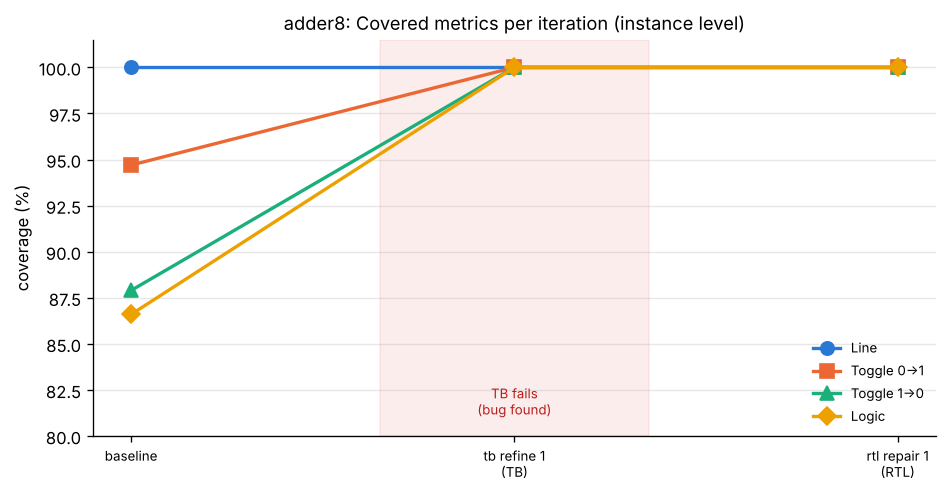

In [27]:
#@title Coverage across iterations
import matplotlib
import matplotlib.pyplot as plt
H = cov_loop.history
labels = ["{}\n{}".format(h["iteration"].replace("_", " "), "(" + h["changed"] + ")" if h["changed"] != "none" else "")
          for h in H]
series = [("line", "Line", "#2a78d6", "o"), ("toggle01", "Toggle 0→1", "#eb6834", "s"),
          ("toggle10", "Toggle 1→0", "#1baf7a", "^"), ("logic", "Logic", "#eda100", "D")]
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=120)
for key, name, color, mk in series:
    ax.plot(range(len(H)), [h[key]["pct"] for h in H], marker=mk, markersize=8, color=color, linewidth=2, label=name)
for i, h in enumerate(H):
    if h["sim_status"] != "passed":
        ax.axvspan(i - 0.35, i + 0.35, color="#dc2626", alpha=0.08)
        ax.text(i, 81, "TB fails\n(bug found)", ha="center", va="bottom", fontsize=8, color="#b91c1c")
ax.set_xticks(range(len(H)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_ylim(80, 101.5)
ax.set_ylabel("coverage (%)")
ax.set_title("adder8: Covered metrics per iteration (instance level)", fontsize=11)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(os.path.join(PART3, "coverage_history.png"))
plt.show()

In [28]:
#@title Final iverilog/vvp commands: final RTL + strongest TB (tb_final.v) pass
final_files = " ".join(os.path.join(PART3, "final_rtl", m + ".v") for m in adder_names)
rc1, _ = sh("iverilog -g2001 -o /tmp/adder8_final.vvp {} {}".format(final_files, os.path.join(PART3, "tb_final.v")))
rc2, out = sh("vvp /tmp/adder8_final.vvp")
assert rc1 == 0 and rc2 == 0 and _simulation_passed(out)
with open(os.path.join(PART3, "final_sim.log"), "w") as f:
    f.write(out)
print("\nFINAL: strongest TB passes on the final RTL; final coverage:",
      {k: cov_loop.history[-1][k]["pct"] for k in ["line", "toggle01", "toggle10", "logic"]})

$ iverilog -g2001 -o /tmp/adder8_final.vvp part3_coverage/final_rtl/half_adder.v part3_coverage/final_rtl/full_adder.v part3_coverage/final_rtl/adder4.v part3_coverage/final_rtl/adder8.v part3_coverage/tb_final.v

$ vvp /tmp/adder8_final.vvp
tests run: 19, mismatches: 0
passed!
part3_coverage/tb_final.v:73: $finish called at 19 (1s)

FINAL: strongest TB passes on the final RTL; final coverage: {'line': 100.0, 'toggle01': 100.0, 'toggle10': 100.0, 'logic': 100.0}


# Part IV — Iteration record (RTL changes vs. TB changes)
One table for the whole extension design: the ROME generation/repair iterations of Part II, then the coverage loop.
Each row changes either the RTL or the testbench, never both.

In [29]:
#@title Combined iteration table
rows = ["| # | phase | module | what changed | testbench used | result |", "|---|---|---|---|---|---|"]
n = 0
for m in adder_names:
    for it, st in rome_iterations(PART2, m):
        n += 1
        rows.append("| {} | ROME loop (Part II) | {} | RTL (LLM {} iteration {}) | {}_tb.v (fixed) | {} |".format(
            n, m, "generation" if it == 0 else "repair", it, m, st))
for h in cov_loop.history:
    n += 1
    what = {"none": "nothing (measure)", "TB": "TB: targeted tests added", "RTL": "RTL: ROME repair, TB frozen"}[h["changed"]]
    rows.append("| {} | {} | adder8 | {} | {} | sim {}; line {}%, tog01 {}%, tog10 {}%, logic {}% |".format(
        n, "coverage loop" if h["changed"] != "RTL" else "ROME loop (Part III)", what, os.path.basename(h["tb_file"]),
        h["sim_status"], h["line"]["pct"], h["toggle01"]["pct"], h["toggle10"]["pct"], h["logic"]["pct"]))
iter_md = "\n".join(rows)
with open(os.path.join(ROOT, "iteration_table.md"), "w") as f:
    f.write(iter_md + "\n")
display(Markdown(iter_md))

| # | phase | module | what changed | testbench used | result |
|---|---|---|---|---|---|
| 1 | ROME loop (Part II) | half_adder | RTL (LLM generation iteration 0) | half_adder_tb.v (fixed) | Testbench ran successfully |
| 2 | ROME loop (Part II) | full_adder | RTL (LLM generation iteration 0) | full_adder_tb.v (fixed) | Testbench ran successfully |
| 3 | ROME loop (Part II) | adder4 | RTL (LLM generation iteration 0) | adder4_tb.v (fixed) | Testbench ran successfully |
| 4 | ROME loop (Part II) | adder8 | RTL (LLM generation iteration 0) | adder8_tb.v (fixed) | Testbench ran successfully |
| 5 | coverage loop | adder8 | nothing (measure) | tb_iter_0.v | sim passed; line 100.0%, tog01 94.7%, tog10 87.9%, logic 86.6% |
| 6 | coverage loop | adder8 | TB: targeted tests added | tb_iter_1.v | sim FAILED; line 100.0%, tog01 100.0%, tog10 100.0%, logic 100.0% |
| 7 | ROME loop (Part III) | adder8 | RTL: ROME repair, TB frozen | tb_iter_1.v | sim passed; line 100.0%, tog01 100.0%, tog10 100.0%, logic 100.0% |

In [30]:
#@title Housekeeping: no credentials in the submission folder
pat = re.compile(r"(sk-[A-Za-z0-9_-]{20,}|sk-ant-[A-Za-z0-9_-]{20,}|AIza[0-9A-Za-z_-]{30,}|hf_[A-Za-z0-9]{30,})")
hits = []
for dp, dn, fn in os.walk(ROOT):
    if ".git" in dp or ".ipynb_checkpoints" in dp:
        continue
    for f in fn:
        p = os.path.join(dp, f)
        try:
            if pat.search(open(p, errors="ignore").read()):
                hits.append(os.path.relpath(p, ROOT))
        except Exception:
            pass
print("files containing something that looks like an API key:", hits or "none")

files containing something that looks like an API key: none
